# Audible Insights: Intelligent Book Recommendations

## 1. Data Preparation and Dataset Merging

### 1.1 Importing Required Libraries

In [2]:
# ==========================================
# 1. IMPORTING REQUIRED LIBRARIES
# ==========================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import KMeans

print("All required libraries imported successfully!")

All required libraries imported successfully!


### 1.2 Loading the Datasets

In [3]:
# 2. LOADING THE DATASETS

import os

base_path = os.path.abspath("..")
data_path = os.path.join(base_path, "data")

file1 = os.path.join(data_path, "Audible_Catlog.csv")
file2 = os.path.join(data_path, "Audible_Catlog_Advanced_Features.csv")

df_basic = pd.read_csv(file1)
df_advanced = pd.read_csv(file2)

print("Basic Dataset Loaded Successfully!")
print("Advanced Dataset Loaded Successfully!")

print("\nBasic Dataset Shape:", df_basic.shape)
print("Advanced Dataset Shape:", df_advanced.shape)

Basic Dataset Loaded Successfully!
Advanced Dataset Loaded Successfully!

Basic Dataset Shape: (6368, 5)
Advanced Dataset Shape: (4464, 8)


### 1.3 Understanding the Datasets

In [4]:
# 3. UNDERSTANDING THE DATASETS

print("========== BASIC DATASET ==========")

print("\nColumn Names:")
print(df_basic.columns.tolist())

print("\nDataset Information:")
df_basic.info()

print("\nMissing Values:")
print(df_basic.isnull().sum())

print("\nFirst 5 Records:")
display(df_basic.head())


print("\n========== ADVANCED DATASET ==========")

print("\nColumn Names:")
print(df_advanced.columns.tolist())

print("\nDataset Information:")
df_advanced.info()

print("\nMissing Values:")
print(df_advanced.isnull().sum())

print("\nFirst 5 Records:")
display(df_advanced.head())

========== BASIC DATASET ==========

Column Names:
['Book Name', 'Author', 'Rating', 'Number of Reviews', 'Price']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6368 entries, 0 to 6367
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Book Name          6368 non-null   object 
 1   Author             6368 non-null   object 
 2   Rating             6368 non-null   float64
 3   Number of Reviews  5737 non-null   float64
 4   Price              6365 non-null   float64
dtypes: float64(3), object(2)
memory usage: 248.9+ KB

Missing Values:
Book Name              0
Author                 0
Rating                 0
Number of Reviews    631
Price                  3
dtype: int64

First 5 Records:


,Book Name,Author,Rating,Number of Reviews,Price
0,Think Like a Monk: The Secret of How to Harnes...,Jay Shetty,4.9,313.0,10080.0
1,Ikigai: The Japanese Secret to a Long and Happ...,Héctor García,4.6,3658.0,615.0
2,The Subtle Art of Not Giving a F*ck: A Counter...,Mark Manson,4.4,20174.0,10378.0
3,Atomic Habits: An Easy and Proven Way to Build...,James Clear,4.6,4614.0,888.0
4,Life's Amazing Secrets: How to Find Balance an...,Gaur Gopal Das,4.6,4302.0,1005.0



========== ADVANCED DATASET ==========

Column Names:
['Book Name', 'Author', 'Rating', 'Number of Reviews', 'Price', 'Description', 'Listening Time', 'Ranks and Genre']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Book Name          4464 non-null   object 
 1   Author             4464 non-null   object 
 2   Rating             4464 non-null   float64
 3   Number of Reviews  4043 non-null   float64
 4   Price              4464 non-null   int64  
 5   Description        4458 non-null   object 
 6   Listening Time     4464 non-null   object 
 7   Ranks and Genre    4464 non-null   object 
dtypes: float64(2), int64(1), object(5)
memory usage: 279.1+ KB

Missing Values:
Book Name              0
Author                 0
Rating                 0
Number of Reviews    421
Price                  0
Description    

,Book Name,Author,Rating,Number of Reviews,Price,Description,Listening Time,Ranks and Genre
0,Think Like a Monk: The Secret of How to Harnes...,Jay Shetty,4.9,371.0,10080,"Over the past three years, Jay Shetty has beco...",10 hours and 54 minutes,",#1 in Audible Audiobooks & Originals (See Top..."
1,Ikigai: The Japanese Secret to a Long and Happ...,Héctor García,4.6,3682.0,615,Brought to you by Penguin.,3 hours and 23 minutes,",#2 in Audible Audiobooks & Originals (See Top..."
2,The Subtle Art of Not Giving a F*ck: A Counter...,Mark Manson,4.4,20306.0,10378,"In this generation-defining self-help guide, a...",5 hours and 17 minutes,",#3 in Audible Audiobooks & Originals (See Top..."
3,Atomic Habits: An Easy and Proven Way to Build...,James Clear,4.6,4678.0,888,Brought to you by Penguin.,5 hours and 35 minutes,",#5 in Audible Audiobooks & Originals (See Top..."
4,Life's Amazing Secrets: How to Find Balance an...,Gaur Gopal Das,4.6,4308.0,1005,"Stop going through life, Start growing throug...",6 hours and 25 minutes,",#6 in Audible Audiobooks & Originals (See Top..."


### 1.4 Checking Common Columns

In [5]:
# 1.3 CHECKING COMMON COLUMNS

print("Basic Dataset Columns:")
print(df_basic.columns.tolist())

print("\nAdvanced Dataset Columns:")
print(df_advanced.columns.tolist())

common_columns = list(
    set(df_basic.columns).intersection(df_advanced.columns)
)

print("\nCommon Columns:")
print(common_columns)

print("\nNumber of Common Columns:", len(common_columns))

Basic Dataset Columns:
['Book Name', 'Author', 'Rating', 'Number of Reviews', 'Price']

Advanced Dataset Columns:
['Book Name', 'Author', 'Rating', 'Number of Reviews', 'Price', 'Description', 'Listening Time', 'Ranks and Genre']

Common Columns:
['Author', 'Price', 'Book Name', 'Rating', 'Number of Reviews']

Number of Common Columns: 5


### 1.5 Preparing Data for Merging

In [6]:


# Create a standardized key using Book Name and Author
for df in [df_basic, df_advanced]:
    df["Book Name"] = df["Book Name"].astype(str).str.strip()
    df["Author"] = df["Author"].astype(str).str.strip()

    df["merge_key"] = (
        df["Book Name"].str.lower() + "_" +
        df["Author"].str.lower()
    )

print("Basic Dataset:")
print("Unique Book-Author Combinations:", df_basic["merge_key"].nunique())

print("\nAdvanced Dataset:")
print("Unique Book-Author Combinations:", df_advanced["merge_key"].nunique())

common_keys = set(df_basic["merge_key"]) & set(df_advanced["merge_key"])

print("\nCommon Book-Author Combinations:", len(common_keys))
print("Basic Dataset Only:", len(set(df_basic["merge_key"]) - set(df_advanced["merge_key"])))
print("Advanced Dataset Only:", len(set(df_advanced["merge_key"]) - set(df_basic["merge_key"])))

Basic Dataset:
Unique Book-Author Combinations: 5402

Advanced Dataset:
Unique Book-Author Combinations: 4011

Common Book-Author Combinations: 3350
Basic Dataset Only: 2052
Advanced Dataset Only: 661


### 1.6 Consolidating Repeated Book-Author Records

In [7]:


# Check repeated book-author combinations
print("Basic Dataset Duplicate Keys:",
      df_basic["merge_key"].duplicated().sum())

print("Advanced Dataset Duplicate Keys:",
      df_advanced["merge_key"].duplicated().sum())

Basic Dataset Duplicate Keys: 966
Advanced Dataset Duplicate Keys: 453


In [8]:
# 3.3.1 CONSOLIDATING REPEATED BOOK-AUTHOR RECORDS

# Keep the record with the highest review count
df_basic = (
    df_basic.sort_values("Number of Reviews", ascending=False)
    .drop_duplicates(subset="merge_key", keep="first")
    .reset_index(drop=True)
)

df_advanced = (
    df_advanced.sort_values("Number of Reviews", ascending=False)
    .drop_duplicates(subset="merge_key", keep="first")
    .reset_index(drop=True)
)

print("Basic Dataset Shape:", df_basic.shape)
print("Advanced Dataset Shape:", df_advanced.shape)

print("\nRemaining Duplicate Keys:")
print("Basic Dataset:", df_basic["merge_key"].duplicated().sum())
print("Advanced Dataset:", df_advanced["merge_key"].duplicated().sum())

Basic Dataset Shape: (5402, 6)
Advanced Dataset Shape: (4011, 9)

Remaining Duplicate Keys:
Basic Dataset: 0
Advanced Dataset: 0


### 1.7 Merging Both Datasets

In [9]:
# 3.3.2 MERGING BASIC AND ADVANCED DATASETS

df_merged = pd.merge(
    df_basic,
    df_advanced,
    on="merge_key",
    how="outer",
    suffixes=("_basic", "_advanced")
)

print("Merged Dataset Shape:", df_merged.shape)

print("\nFirst 5 Records:")
display(df_merged.head())

print("\nMissing Values in Merged Dataset:")
print(df_merged.isnull().sum())

Merged Dataset Shape: (6063, 14)

First 5 Records:


,Book Name_basic,Author_basic,Rating_basic,Number of Reviews_basic,Price_basic,merge_key,Book Name_advanced,Author_advanced,Rating_advanced,Number of Reviews_advanced,Price_advanced,Description,Listening Time,Ranks and Genre
0,"""Don't You Know Who I Am?"": How to Stay Sane i...",Ramani S. Durvasula PhD,4.8,170.0,836.0,"""don't you know who i am?"": how to stay sane i...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,#Girlboss,Sophia Amoruso,4.5,2260.0,615.0,#girlboss_sophia amoruso,#Girlboss,Sophia Amoruso,4.5,2272.0,615.0,"Penguin presents the unabridged downloadable, ...",-1,-1
2,#TheRealCinderella: #BestFriendsForever Series...,Yesenia Vargas,4.3,179.0,586.0,#therealcinderella: #bestfriendsforever series...,#TheRealCinderella: #BestFriendsForever Series...,Yesenia Vargas,4.3,179.0,586.0,\n\nOops!\nIt's rush hour and traffic is pilin...,-1,-1
3,10 Bedtime Stories For Little Kids,div.,-1.0,NaN,376.0,10 bedtime stories for little kids_div.,10 Bedtime Stories For Little Kids,div.,-1.0,NaN,376.0,\nBy completing your purchase you agree to Aud...,-1,-1
4,10 Essential Pieces of Literature,Khalil Gibran,-1.0,NaN,32.0,10 essential pieces of literature_khalil gibran,10 Essential Pieces of Literature,Khalil Gibran,-1.0,NaN,32.0,This Audiobook contains the following works:,87 hours and 44 minutes,",#759 in Audible Audiobooks & Originals (See T..."



Missing Values in Merged Dataset:
Book Name_basic                661
Author_basic                   661
Rating_basic                   661
Number of Reviews_basic       1183
Price_basic                    663
merge_key                        0
Book Name_advanced            2052
Author_advanced               2052
Rating_advanced               2052
Number of Reviews_advanced    2429
Price_advanced                2052
Description                   2058
Listening Time                2052
Ranks and Genre               2052
dtype: int64


### 1.8 Verifying the Merged Dataset

In [10]:


print("Merged Dataset Columns:")
print(df_merged.columns.tolist())

print("\nMerged Dataset Shape:")
print(df_merged.shape)

print("\nSample Book Records:")
display(
    df_merged[
        [
            "Book Name_basic",
            "Author_basic",
            "Book Name_advanced",
            "Author_advanced"
        ]
    ].head(10)
)

matched = (
    df_merged["Book Name_basic"].notna()
    & df_merged["Book Name_advanced"].notna()
)

print("\nNumber of Matched Records:", matched.sum())

Merged Dataset Columns:
['Book Name_basic', 'Author_basic', 'Rating_basic', 'Number of Reviews_basic', 'Price_basic', 'merge_key', 'Book Name_advanced', 'Author_advanced', 'Rating_advanced', 'Number of Reviews_advanced', 'Price_advanced', 'Description', 'Listening Time', 'Ranks and Genre']

Merged Dataset Shape:
(6063, 14)

Sample Book Records:


,Book Name_basic,Author_basic,Book Name_advanced,Author_advanced
0,"""Don't You Know Who I Am?"": How to Stay Sane i...",Ramani S. Durvasula PhD,NaN,NaN
1,#Girlboss,Sophia Amoruso,#Girlboss,Sophia Amoruso
2,#TheRealCinderella: #BestFriendsForever Series...,Yesenia Vargas,#TheRealCinderella: #BestFriendsForever Series...,Yesenia Vargas
3,10 Bedtime Stories For Little Kids,div.,10 Bedtime Stories For Little Kids,div.
4,10 Essential Pieces of Literature,Khalil Gibran,10 Essential Pieces of Literature,Khalil Gibran
5,10 Essential Success Mantras from the Bhagavad...,Vimla Patil,10 Essential Success Mantras from the Bhagavad...,Vimla Patil
6,10 Judgements That Changed India,Zia Mody,NaN,NaN
7,10 Masterpieces You Have to Read Before You Die 1,Jane Austen,10 Masterpieces You Have to Read Before You Die 1,Jane Austen
8,10 Minutes 38 Seconds in This Strange World,Elif Shafak,10 Minutes 38 Seconds in This Strange World,Elif Shafak
9,10 Skills for Effective Business Communication...,Jessica Higgins JD MBA BB,10 Skills for Effective Business Communication...,Jessica Higgins JD MBA BB



Number of Matched Records: 3350


In [11]:
matched = (
    df_merged["Book Name_basic"].notna()
    & df_merged["Book Name_advanced"].notna()
)

basic_only = (
    df_merged["Book Name_basic"].notna()
    & df_merged["Book Name_advanced"].isna()
)

advanced_only = (
    df_merged["Book Name_basic"].isna()
    & df_merged["Book Name_advanced"].notna()
)

print("Total Merged Records:", len(df_merged))
print("Matched Records:", matched.sum())
print("Basic Dataset Only:", basic_only.sum())
print("Advanced Dataset Only:", advanced_only.sum())

Total Merged Records: 6063
Matched Records: 3350
Basic Dataset Only: 2052
Advanced Dataset Only: 661


### 1.9 Checking Merge Key Matching

In [12]:


print("Unique Basic Keys:", df_basic["merge_key"].nunique())
print("Unique Advanced Keys:", df_advanced["merge_key"].nunique())

common_keys = set(df_basic["merge_key"]) & set(df_advanced["merge_key"])

print("Common Keys:", len(common_keys))

print("\nSample Common Keys:")
print(list(common_keys)[:10])

print("\nChecking Merge Key Matches:")

key_check = pd.merge(
    df_basic[["merge_key"]],
    df_advanced[["merge_key"]],
    on="merge_key",
    how="inner"
)

print("Matched Keys:", len(key_check))

Unique Basic Keys: 5402
Unique Advanced Keys: 4011
Common Keys: 3350

Sample Common Keys:
['soar!: build your vision from the ground up_t. d. jakes', "hbr's 10 must reads on design thinking: hbr's 10 must reads series_harvard business review", 'social media marketing 2020 mastery 4 books bundle: how to create a brand. become a skilled influencer on twitter, facebook, youtube, instagram: personal branding & digital networking strategies_brandon j. artley', 'six days of war: june 1967 and the making of the modern middle east_michael b. oren', 'storm in a teacup: the physics of everyday life_helen czerski', 'making it all work: winning at the game of work and the business of life_david allen', 'the hindu view of life_s. radhakrishnan', 'the winter of the witch: winternight trilogy, book 3_katherine arden', "nightmarch: a journey into india's naxal heartlands_alpa shah", 'something blue_emily giffin']

Checking Merge Key Matches:
Matched Keys: 3350


In [13]:
matched = (
    df_merged["Book Name_basic"].notna()
    & df_merged["Book Name_advanced"].notna()
)

basic_only = (
    df_merged["Book Name_basic"].notna()
    & df_merged["Book Name_advanced"].isna()
)

advanced_only = (
    df_merged["Book Name_basic"].isna()
    & df_merged["Book Name_advanced"].notna()
)

print("Total Merged Records:", len(df_merged))
print("Matched Records:", matched.sum())
print("Basic Dataset Only:", basic_only.sum())
print("Advanced Dataset Only:", advanced_only.sum())

Total Merged Records: 6063
Matched Records: 3350
Basic Dataset Only: 2052
Advanced Dataset Only: 661


### 1.10 Creating the Final Unified Dataset

In [14]:
# Create the final unified dataset

df_final = pd.DataFrame()

# Combine common columns (prefer Advanced Dataset values)
for column in ["Book Name", "Author", "Rating", "Number of Reviews", "Price"]:
    df_final[column] = (
        df_merged[f"{column}_advanced"]
        .combine_first(df_merged[f"{column}_basic"])
    )

# Add advanced dataset features
df_final["Description"] = df_merged["Description"]
df_final["Listening Time"] = df_merged["Listening Time"]
df_final["Ranks and Genre"] = df_merged["Ranks and Genre"]

# Check final dataset
print("Final Unified Dataset Shape:", df_final.shape)
print("\nFinal Dataset Columns:")
print(df_final.columns.tolist())

display(df_final.head())

Final Unified Dataset Shape: (6063, 8)

Final Dataset Columns:
['Book Name', 'Author', 'Rating', 'Number of Reviews', 'Price', 'Description', 'Listening Time', 'Ranks and Genre']


,Book Name,Author,Rating,Number of Reviews,Price,Description,Listening Time,Ranks and Genre
0,"""Don't You Know Who I Am?"": How to Stay Sane i...",Ramani S. Durvasula PhD,4.8,170.0,836.0,NaN,NaN,NaN
1,#Girlboss,Sophia Amoruso,4.5,2272.0,615.0,"Penguin presents the unabridged downloadable, ...",-1,-1
2,#TheRealCinderella: #BestFriendsForever Series...,Yesenia Vargas,4.3,179.0,586.0,\n\nOops!\nIt's rush hour and traffic is pilin...,-1,-1
3,10 Bedtime Stories For Little Kids,div.,-1.0,NaN,376.0,\nBy completing your purchase you agree to Aud...,-1,-1
4,10 Essential Pieces of Literature,Khalil Gibran,-1.0,NaN,32.0,This Audiobook contains the following works:,87 hours and 44 minutes,",#759 in Audible Audiobooks & Originals (See T..."


## 2. Data Cleaning

### 2.1 Checking Missing Values

In [15]:
# Check missing values in the final dataset

print("Missing Values in Each Column:")
print(df_final.isnull().sum())

print("\nTotal Missing Values:")
print(df_final.isnull().sum().sum())

print("\nDataset Information:")
df_final.info()

Missing Values in Each Column:
Book Name               0
Author                  0
Rating                  0
Number of Reviews     580
Price                   1
Description          2058
Listening Time       2052
Ranks and Genre      2052
dtype: int64

Total Missing Values:
6743

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6063 entries, 0 to 6062
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Book Name          6063 non-null   object 
 1   Author             6063 non-null   object 
 2   Rating             6063 non-null   float64
 3   Number of Reviews  5483 non-null   float64
 4   Price              6062 non-null   float64
 5   Description        4005 non-null   object 
 6   Listening Time     4011 non-null   object 
 7   Ranks and Genre    4011 non-null   object 
dtypes: float64(3), object(5)
memory usage: 379.1+ KB


### 2.2 Handling Missing Numerical Values

In [16]:
# Fill missing Number of Reviews with median
df_final["Number of Reviews"] = (
    df_final["Number of Reviews"].fillna(
        df_final["Number of Reviews"].median()
    )
)

# Fill missing Price with median
df_final["Price"] = (
    df_final["Price"].fillna(
        df_final["Price"].median()
    )
)

# Verify missing values
print("Missing Values After Numerical Cleaning:")
print(df_final[["Number of Reviews", "Price"]].isnull().sum())

print("\nUpdated Dataset Shape:", df_final.shape)

Missing Values After Numerical Cleaning:
Number of Reviews    0
Price                0
dtype: int64

Updated Dataset Shape: (6063, 8)


### 2.3 Handling Missing Text Values

In [17]:
# Fill missing Description values
df_final["Description"] = df_final["Description"].fillna(
    "Description not available"
)

# Fill missing Listening Time values
df_final["Listening Time"] = df_final["Listening Time"].fillna(
    "Not available"
)

# Fill missing Ranks and Genre values
df_final["Ranks and Genre"] = df_final["Ranks and Genre"].fillna(
    "Not available"
)

# Verify missing values
print("Missing Values After Text Cleaning:")
print(df_final.isnull().sum())

print("\nTotal Missing Values:", df_final.isnull().sum().sum())

Missing Values After Text Cleaning:
Book Name            0
Author               0
Rating               0
Number of Reviews    0
Price                0
Description          0
Listening Time       0
Ranks and Genre      0
dtype: int64

Total Missing Values: 0


### 2.4 Handling Invalid Ratings

In [18]:
# Check rating distribution
print("Rating Value Counts:")
print(df_final["Rating"].value_counts().sort_index())

# Count invalid ratings
invalid_ratings = (df_final["Rating"] == -1).sum()

print("\nNumber of Invalid Ratings:", invalid_ratings)

# Check valid rating range
print("\nMinimum Rating:", df_final["Rating"].min())
print("Maximum Rating:", df_final["Rating"].max())

Rating Value Counts:
Rating
-1.0    580
 1.0      8
 1.8      1
 1.9      2
 2.0      4
 2.4      2
 2.5      5
 2.6      4
 2.7      3
 2.8      1
 2.9      6
 3.0     15
 3.1      8
 3.2      9
 3.3      8
 3.4     20
 3.5     18
 3.6     19
 3.7     44
 3.8     53
 3.9     78
 4.0    140
 4.1    195
 4.2    325
 4.3    493
 4.4    694
 4.5    883
 4.6    981
 4.7    832
 4.8    393
 4.9     88
 5.0    151
Name: count, dtype: int64

Number of Invalid Ratings: 580

Minimum Rating: -1.0
Maximum Rating: 5.0


### 2.5 Replacing Invalid Ratings

In [19]:
import numpy as np

# Replace invalid rating (-1) with NaN
df_final["Rating"] = df_final["Rating"].replace(-1, np.nan)

# Calculate median using valid ratings only
valid_rating_median = df_final["Rating"].median()

# Fill missing ratings with median
df_final["Rating"] = df_final["Rating"].fillna(valid_rating_median)

# Verify the changes
print("Median Rating:", valid_rating_median)
print("\nRemaining Missing Ratings:", df_final["Rating"].isnull().sum())
print("Minimum Rating:", df_final["Rating"].min())
print("Maximum Rating:", df_final["Rating"].max())
print("\nUpdated Rating Distribution:")
print(df_final["Rating"].value_counts().sort_index())

Median Rating: 4.5

Remaining Missing Ratings: 0
Minimum Rating: 1.0
Maximum Rating: 5.0

Updated Rating Distribution:
Rating
1.0       8
1.8       1
1.9       2
2.0       4
2.4       2
2.5       5
2.6       4
2.7       3
2.8       1
2.9       6
3.0      15
3.1       8
3.2       9
3.3       8
3.4      20
3.5      18
3.6      19
3.7      44
3.8      53
3.9      78
4.0     140
4.1     195
4.2     325
4.3     493
4.4     694
4.5    1463
4.6     981
4.7     832
4.8     393
4.9      88
5.0     151
Name: count, dtype: int64


### 2.6 Checking and Removing Duplicate Records

In [20]:
# Check duplicate records
print("Total Duplicate Rows:", df_final.duplicated().sum())

# Check duplicate books based on Book Name and Author
print(
    "Duplicate Book-Author Records:",
    df_final.duplicated(subset=["Book Name", "Author"]).sum()
)

Total Duplicate Rows: 0
Duplicate Book-Author Records: 0


### 2.7 Standardizing Text Data

In [21]:
# Remove leading and trailing spaces
df_final["Book Name"] = df_final["Book Name"].str.strip()
df_final["Author"] = df_final["Author"].str.strip()

# Standardize text case
df_final["Book Name"] = df_final["Book Name"].str.title()
df_final["Author"] = df_final["Author"].str.title()

# Clean Description text
df_final["Description"] = (
    df_final["Description"].astype(str).str.strip()
)

# Clean Listening Time and Ranks and Genre
df_final["Listening Time"] = (
    df_final["Listening Time"].astype(str).str.strip()
)

df_final["Ranks and Genre"] = (
    df_final["Ranks and Genre"].astype(str).str.strip()
)

# Display cleaned records
display(df_final.head())

print("\nDataset Shape:", df_final.shape)

,Book Name,Author,Rating,Number of Reviews,Price,Description,Listening Time,Ranks and Genre
0,"""Don'T You Know Who I Am?"": How To Stay Sane I...",Ramani S. Durvasula Phd,4.8,170.0,836.0,Description not available,Not available,Not available
1,#Girlboss,Sophia Amoruso,4.5,2272.0,615.0,"Penguin presents the unabridged downloadable, ...",-1,-1
2,#Therealcinderella: #Bestfriendsforever Series...,Yesenia Vargas,4.3,179.0,586.0,Oops!\nIt's rush hour and traffic is piling up...,-1,-1
3,10 Bedtime Stories For Little Kids,Div.,4.5,239.0,376.0,By completing your purchase you agree to Audib...,-1,-1
4,10 Essential Pieces Of Literature,Khalil Gibran,4.5,239.0,32.0,This Audiobook contains the following works:,87 hours and 44 minutes,",#759 in Audible Audiobooks & Originals (See T..."



Dataset Shape: (6063, 8)


### 2.8 Identifying Invalid Text Values

In [22]:
# Check invalid placeholders in Listening Time and Ranks and Genre
print("Listening Time Value Counts:")
print(df_final["Listening Time"].value_counts().head(10))

print("\nRanks and Genre Value Counts:")
print(df_final["Ranks and Genre"].value_counts().head(10))

# Check suspicious descriptions
print("\nSample Descriptions:")
display(df_final[["Book Name", "Description"]].sample(10, random_state=42))

Listening Time Value Counts:
Listening Time
Not available              2052
-1                         1976
11 hours and 4 minutes        9
8 hours and 49 minutes        7
5 hours and 30 minutes        7
23 minutes                    7
14 hours and 20 minutes       7
7 hours and 54 minutes        7
7 hours and 11 minutes        7
8 hours and 10 minutes        6
Name: count, dtype: int64

Ranks and Genre Value Counts:
Ranks and Genre
Not available                                                                                                                                                                                           2052
-1                                                                                                                                                                                                      1976
,          5 star,        ,          (0%),        ,          ,            0%,          ,                                                                 

,Book Name,Description
476,Atlas Shrugged,In defense of those greatest of human qualitie...
1393,F.U. Money: Make As Much Money As You Damn Wel...,Are you tired of the rat race? Do you wish you...
5077,The Pregnant King,"""‘I am not sure that I am a man,’ said Yuvanas..."
2972,Operation Paperclip: The Secret Intelligence P...,"The explosive, dark secrets behind America's p..."
5716,Uncle Fred In The Springtime,Description not available
3550,Sita Ke Paanch Nirnay [Sita Or Five Decisions],This is a collection of some of the best stori...
1874,How The Scots Invented The Modern World,"Sorry, we just need to make sure you're not a ..."
1916,How To Measure Anything In Cybersecurity Risk,Description not available
576,"Belong: Find Your People, Create Community & L...",Description not available
3413,Science In The Soul: Selected Writings Of A Pa...,"Richard Dawkins - author of The Selfish Gene, ..."


### 2.9 Cleaning Invalid Metadata Values

In [23]:
# Replace invalid -1 values with Not available

df_final["Listening Time"] = df_final["Listening Time"].replace(
    "-1", "Not available"
)

df_final["Ranks and Genre"] = df_final["Ranks and Genre"].replace(
    "-1", "Not available"
)

# Verify changes
print("Listening Time:")
print(df_final["Listening Time"].value_counts().head())

print("\nRanks and Genre:")
print(df_final["Ranks and Genre"].value_counts().head())

Listening Time:
Listening Time
Not available             4028
11 hours and 4 minutes       9
23 minutes                   7
8 hours and 49 minutes       7
5 hours and 30 minutes       7
Name: count, dtype: int64

Ranks and Genre:
Ranks and Genre
Not available                                                                               4028
,          5 star,        ,          (0%),        ,          ,            0%,          ,      14
,            5 star,          ,            ,              81%,            ,                    3
,            5 star,          ,            ,              80%,            ,                    2
,            5 star,          ,            ,              100%,            ,                   2
Name: count, dtype: int64


### 2.10 Cleaning Invalid Descriptions

In [25]:
import re

# Identify website error messages, including messages with line breaks
error_pattern = (
    r"sorry,\s*we just need to make sure"
    r"|oops!\s*it's rush hour"
    r"|by completing your purchase"
)

# Count descriptions containing error messages
error_mask = df_final["Description"].str.contains(
    error_pattern, case=False, na=False, regex=True
)

print("Invalid Descriptions Found:", error_mask.sum())

# Replace invalid descriptions
df_final.loc[error_mask, "Description"] = "Description not available"

# Verify cleaning
print("\nDescriptions After Cleaning:")
print(df_final["Description"].value_counts().head())

print("\nRemaining Missing Values:")
print(df_final.isnull().sum().sum())

Invalid Descriptions Found: 552

Descriptions After Cleaning:
Description
Description not available                                                                                                                                                                                                                                                                                                                                                                                                                                                              3644
Brought to you by Penguin.                                                                                                                                                                                                                                                                                                                                                                                                                                        

### 2.11 Understanding Genre Information

In [26]:
# Display sample values from the Ranks and Genre column
genre_samples = df_final.loc[
    df_final["Ranks and Genre"] != "Not available",
    "Ranks and Genre"
].sample(10, random_state=42)

for value in genre_samples:
    print(value)
    print("-" * 80)

,#1,300 in Audible Audiobooks & Originals (See Top 100 in Audible Audiobooks & Originals),#52 in Personal Finance,#58 in Investing & Trading,#2,080 in Analysis & Strategy
--------------------------------------------------------------------------------
,#578 in Audible Audiobooks & Originals (See Top 100 in Audible Audiobooks & Originals),#4 in Computer Science (Audible Audiobooks & Originals),#12 in Business Decision Making & Problem Solving,#25 in Science
--------------------------------------------------------------------------------
,#4,194 in Audible Audiobooks & Originals (See Top 100 in Audible Audiobooks & Originals),#28 in Romance for Teens,#275 in Literature & Fiction for Children,#493 in Painting (Books)
--------------------------------------------------------------------------------
,#2,165 in Audible Audiobooks & Originals (See Top 100 in Audible Audiobooks & Originals),#4 in Small Town & Rural Fiction,#4 in 20th Century Historical Romance,#32 in Family Life Fiction
-------

### 2.12 Extracting Genres

In [39]:
import re

def extract_genres(value):

    if pd.isna(value) or value == "Not available":
        return "Unknown"

    matches = re.findall(
        r"#\s*[\d,]+\s+in\s+(.*?)(?=,\s*#\s*[\d,]+\s+in\s+|$)",
        str(value)
    )

    genres = []

    for genre in matches:

        # Remove additional information in parentheses
        genre = re.sub(r"\s*\([^)]*\)", "", genre).strip()

        # Ignore the overall Audible category
        if genre and genre.lower() != "audible audiobooks & originals":

            if genre not in genres:
                genres.append(genre)

    # Use | as a separator to preserve commas within genre names
    return " | ".join(genres) if genres else "Unknown"


# Extract genres
df_final["Genre"] = df_final["Ranks and Genre"].apply(extract_genres)

print("Genre Extraction Examples:")

display(
    df_final[
        ["Book Name", "Ranks and Genre", "Genre"]
    ].head(15)
)

print("\nUnique Genre Values:", df_final["Genre"].nunique())

print(
    "\nUnknown Genre Records:",
    (df_final["Genre"] == "Unknown").sum()
)

Genre Extraction Examples:


,Book Name,Ranks and Genre,Genre
0,"""Don'T You Know Who I Am?"": How To Stay Sane In An Era Of Narcissism, Entitlement, And Incivility",Not available,Unknown
1,#Girlboss,Not available,Unknown
2,"#Therealcinderella: #Bestfriendsforever Series, Book 1",Not available,Unknown
3,10 Bedtime Stories For Little Kids,Not available,Unknown
4,10 Essential Pieces Of Literature,",#759 in Audible Audiobooks & Originals (See Top 100 in Audible Audiobooks & Originals),#40 in Classic Literature,#777 in Classic Fiction (Books)",Classic Literature | Classic Fiction
5,10 Essential Success Mantras From The Bhagavad Gita (Rupa Quick Reads),",#3,076 in Audible Audiobooks & Originals (See Top 100 in Audible Audiobooks & Originals),#45 in Hinduism (Audible Audiobooks & Originals),#57 in Forecasting & Strategic Planning,#136 in Leadership",Hinduism | Forecasting & Strategic Planning | Leadership
6,10 Judgements That Changed India,Not available,Unknown
7,10 Masterpieces You Have To Read Before You Die 1,",#1,485 in Audible Audiobooks & Originals (See Top 100 in Audible Audiobooks & Originals),#4 in Caribbean & Latin American Literature,#6 in English, Irish, Scottish & Welsh Literature,#77 in Classic Literature","Caribbean & Latin American Literature | English, Irish, Scottish & Welsh Literature | Classic Literature"
8,10 Minutes 38 Seconds In This Strange World,",#221 in Audible Audiobooks & Originals (See Top 100 in Audible Audiobooks & Originals),#1 in Friendship Fiction,#3 in Women's Fiction,#3 in Political Fiction",Friendship Fiction | Women's Fiction | Political Fiction
9,10 Skills For Effective Business Communication: Practical Strategies From The World'S Greatest Leaders,Not available,Unknown



Unique Genre Values: 1568

Unknown Genre Records: 4066


In [40]:
# Count individual genres without splitting commas inside genre names
genre_counts = (
    df_final[df_final["Genre"] != "Unknown"]["Genre"]
    .str.split(" | ", regex=False)
    .explode()
    .str.strip()
    .value_counts()
)

print("Total Individual Genres:", len(genre_counts))

print("\nTop 20 Most Common Genres:")
display(genre_counts.head(20))

Total Individual Genres: 865

Top 20 Most Common Genres:


Genre
Personal Success                    196
Personal Development & Self-Help    156
Textbooks & Study Guides            117
Analysis & Strategy                 117
Classic Literature                   82
Leadership                           73
Contemporary Fiction                 71
Literary Fiction                     66
Crime, Thriller & Mystery            60
Biographies & Autobiographies        57
Historical Fiction                   51
Classic Fiction                      49
Romance                              47
Contemporary Romance                 47
Psychology                           47
Business Management                  46
Mind, Body & Spirit                  45
Meditation                           44
Personal Finance                     42
Business Careers                     42
Name: count, dtype: int64

In [42]:
# Save the final cleaned dataset

df_final.to_csv("../data/audible_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")
print("Dataset Shape:", df_final.shape)


Cleaned dataset saved successfully!
Dataset Shape: (6063, 10)


## 3. Exploratory Data Analysis (EDA)

### 3.1 Loading the Cleaned Dataset

In [43]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the cleaned dataset
df = pd.read_csv("../data/audible_cleaned.csv")

# Display dataset details
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Preview:")
display(df.head())

print("\nDataset Information:")
df.info()

Dataset Shape: (6063, 10)

Column Names:
['Book Name', 'Author', 'Rating', 'Number of Reviews', 'Price', 'Description', 'Listening Time', 'Ranks and Genre', 'Genre', 'Listening_Time_Minutes']

Dataset Preview:


,Book Name,Author,Rating,Number of Reviews,Price,Description,Listening Time,Ranks and Genre,Genre,Listening_Time_Minutes
0,"""Don'T You Know Who I Am?"": How To Stay Sane In An Era Of Narcissism, Entitlement, And Incivility",Ramani S. Durvasula Phd,4.8,170.0,836.0,Description not available,Not available,Not available,Unknown,NaN
1,#Girlboss,Sophia Amoruso,4.5,2272.0,615.0,"Penguin presents the unabridged downloadable, audiobook edition of #Girlboss by Sophia Amoruso, read by Sarah Jes Austell. The first thing Sophia Amoruso sold online wasn't fashion. It was a stolen book. At age 17 she was a dumpster-diving, shoplifting anarchist. By 29 she was the founder and CEO of Nasty Gal, a $100 million-plus fashion empire.",Not available,Not available,Unknown,NaN
2,"#Therealcinderella: #Bestfriendsforever Series, Book 1",Yesenia Vargas,4.3,179.0,586.0,Description not available,Not available,Not available,Unknown,NaN
3,10 Bedtime Stories For Little Kids,Div.,4.5,239.0,376.0,Description not available,Not available,Not available,Unknown,NaN
4,10 Essential Pieces Of Literature,Khalil Gibran,4.5,239.0,32.0,This Audiobook contains the following works:,87 hours and 44 minutes,",#759 in Audible Audiobooks & Originals (See Top 100 in Audible Audiobooks & Originals),#40 in Classic Literature,#777 in Classic Fiction (Books)",Classic Literature | Classic Fiction,5264.0



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6063 entries, 0 to 6062
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Book Name               6063 non-null   object 
 1   Author                  6063 non-null   object 
 2   Rating                  6063 non-null   float64
 3   Number of Reviews       6063 non-null   float64
 4   Price                   6063 non-null   float64
 5   Description             6061 non-null   object 
 6   Listening Time          6063 non-null   object 
 7   Ranks and Genre         6063 non-null   object 
 8   Genre                   6063 non-null   object 
 9   Listening_Time_Minutes  2033 non-null   float64
dtypes: float64(4), object(6)
memory usage: 473.8+ KB


In [44]:
print("Missing Values in Each Column:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values in Each Column:
Book Name                    0
Author                       0
Rating                       0
Number of Reviews            0
Price                        0
Description                  2
Listening Time               0
Ranks and Genre              0
Genre                        0
Listening_Time_Minutes    4030
dtype: int64

Total Missing Values: 4032


In [45]:
df["Description"] = df["Description"].fillna(
    "Description not available"
)

df.to_csv("../data/audible_cleaned.csv", index=False)

print("Missing descriptions handled successfully!")
print("\nRemaining Missing Values:")
print(df.isnull().sum())

Missing descriptions handled successfully!

Remaining Missing Values:
Book Name                    0
Author                       0
Rating                       0
Number of Reviews            0
Price                        0
Description                  0
Listening Time               0
Ranks and Genre              0
Genre                        0
Listening_Time_Minutes    4030
dtype: int64


### 3.2 Genre Distribution Analysis


**Project Question:**

What are the most popular genres in the dataset?

**Objective:**

To identify the most common book genres in the Audible catalogue by counting the number of books belonging to each genre.

In [46]:
# Count individual genres across books

genre_counts = (
    df[df["Genre"] != "Unknown"]["Genre"]
    .str.split(" | ", regex=False)
    .explode()
    .str.strip()
    .value_counts()
)

print("Total Individual Genres:", len(genre_counts))

print("\nTop 20 Most Common Genres:")
display(genre_counts.head(20))

Total Individual Genres: 865

Top 20 Most Common Genres:


Genre
Personal Success                    196
Personal Development & Self-Help    156
Textbooks & Study Guides            117
Analysis & Strategy                 117
Classic Literature                   82
Leadership                           73
Contemporary Fiction                 71
Literary Fiction                     66
Crime, Thriller & Mystery            60
Biographies & Autobiographies        57
Historical Fiction                   51
Classic Fiction                      49
Romance                              47
Contemporary Romance                 47
Psychology                           47
Business Management                  46
Mind, Body & Spirit                  45
Meditation                           44
Personal Finance                     42
Business Careers                     42
Name: count, dtype: int64

### 3.3 Rating Distribution

In [47]:
# Analyze book rating statistics

print("Rating Statistics:")
display(df["Rating"].describe())

print("\nRating Counts:")
display(df["Rating"].value_counts().sort_index())

Rating Statistics:


count    6063.000000
mean        4.461075
std         0.333496
min         1.000000
25%         4.400000
50%         4.500000
75%         4.600000
max         5.000000
Name: Rating, dtype: float64


Rating Counts:


Rating
1.0       8
1.8       1
1.9       2
2.0       4
2.4       2
2.5       5
2.6       4
2.7       3
2.8       1
2.9       6
3.0      15
3.1       8
3.2       9
3.3       8
3.4      20
3.5      18
3.6      19
3.7      44
3.8      53
3.9      78
4.0     140
4.1     195
4.2     325
4.3     493
4.4     694
4.5    1463
4.6     981
4.7     832
4.8     393
4.9      88
5.0     151
Name: count, dtype: int64

#### 3.3.1 Rating Distribution Visualization

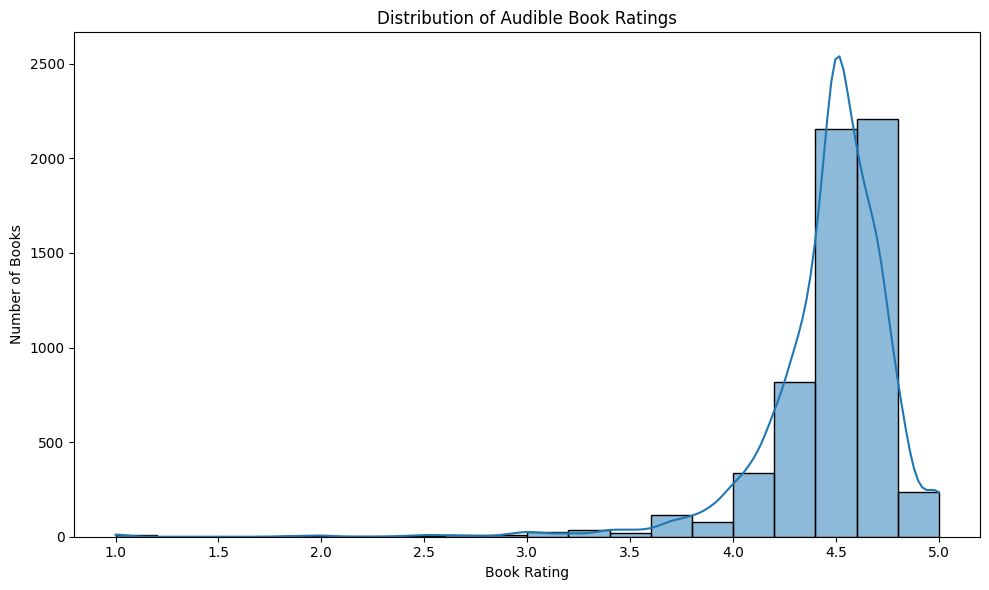

In [48]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="Rating",
    bins=20,
    kde=True
)

plt.title("Distribution of Audible Book Ratings")
plt.xlabel("Book Rating")
plt.ylabel("Number of Books")

plt.tight_layout()
plt.show()

**Key Observations:**

- Most Audible books have ratings between 4.0 and 5.0.
- The average rating is approximately 4.46.
- The highest concentration of ratings is around 4.5 to 4.7.
- Very few books have ratings below 3.5.
- The dataset indicates generally positive ratings for Audible books.
- The distribution may be influenced by median imputation of 580 invalid ratings.

### 3.4 Highest-Rated Authors

**Project Question:**

Which authors have the highest-rated books?

In [49]:
# Calculate average rating and book count for each author

author_ratings = (
    df.groupby("Author")
    .agg(
        Average_Rating=("Rating", "mean"),
        Total_Books=("Book Name", "count")
    )
    .reset_index()
)

# Consider authors with at least 5 books
popular_authors = author_ratings[
    author_ratings["Total_Books"] >= 5
]

# Display top 10 highest-rated authors
top_authors = popular_authors.sort_values(
    by="Average_Rating",
    ascending=False
).head(10)

print("Top 10 Highest-Rated Authors:")
display(top_authors)

Top 10 Highest-Rated Authors:


,Author,Average_Rating,Total_Books
3686,Tui T. Sutherland,4.855556,9
87,Alan Watts,4.800000,5
2641,Norman Bridwell,4.780000,5
2335,Mary Pope Osborne,4.771429,7
771,Dav Pilkey,4.760000,5
2159,Liz Pichon,4.750000,14
2593,Neville Goddard,4.733333,6
3219,Sarah J. Maas,4.720000,10
557,Cassandra Clare,4.714286,7
484,Brené Brown,4.700000,6


#### 3.4.1 Top 10 Highest-Rated Authors

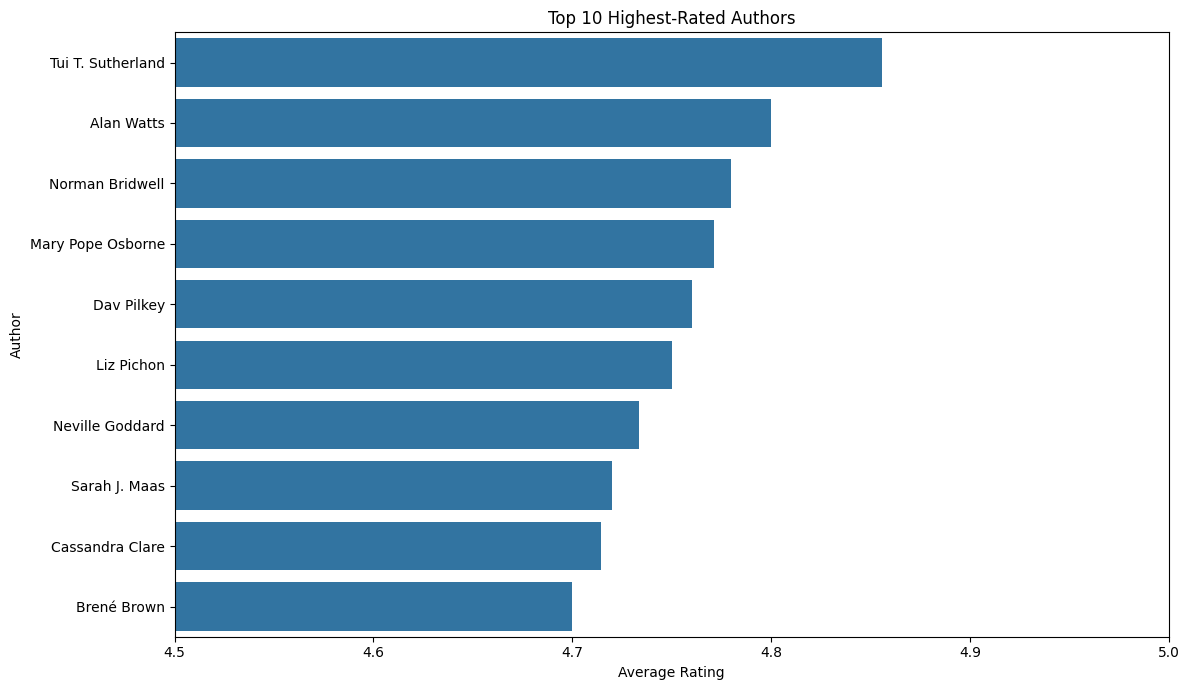

In [50]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_authors,
    x="Average_Rating",
    y="Author"
)

plt.title("Top 10 Highest-Rated Authors")
plt.xlabel("Average Rating")
plt.ylabel("Author")
plt.xlim(4.5, 5.0)

plt.tight_layout()
plt.show()

**Key Observations:**

- Tui T. Sutherland has the highest average rating of approximately 4.86.
- Alan Watts ranks second with an average rating of 4.80.
- All selected authors have average ratings of 4.70 or above.
- Liz Pichon has the highest number of books among the top 10 authors, with 14 books.
- The results indicate that these authors have consistently high book ratings in the dataset.

### 3.5 Average Rating Distribution Across Books

**Project Question:**

What is the average rating distribution across books?

**Objective:**

To analyze the distribution of book ratings and understand the overall rating patterns in the Audible catalogue.

In [51]:
# Calculate rating statistics

print("Total Number of Books:", len(df))

print("\nAverage Rating:", round(df["Rating"].mean(), 2))
print("Median Rating:", round(df["Rating"].median(), 2))
print("Standard Deviation:", round(df["Rating"].std(), 2))
print("Minimum Rating:", df["Rating"].min())
print("Maximum Rating:", df["Rating"].max())

print("\nRating Distribution:")
display(df["Rating"].value_counts().sort_index())

Total Number of Books: 6063

Average Rating: 4.46
Median Rating: 4.5
Standard Deviation: 0.33
Minimum Rating: 1.0
Maximum Rating: 5.0

Rating Distribution:


Rating
1.0       8
1.8       1
1.9       2
2.0       4
2.4       2
2.5       5
2.6       4
2.7       3
2.8       1
2.9       6
3.0      15
3.1       8
3.2       9
3.3       8
3.4      20
3.5      18
3.6      19
3.7      44
3.8      53
3.9      78
4.0     140
4.1     195
4.2     325
4.3     493
4.4     694
4.5    1463
4.6     981
4.7     832
4.8     393
4.9      88
5.0     151
Name: count, dtype: int64

#### 3.5.2 Rating Distribution Visualization

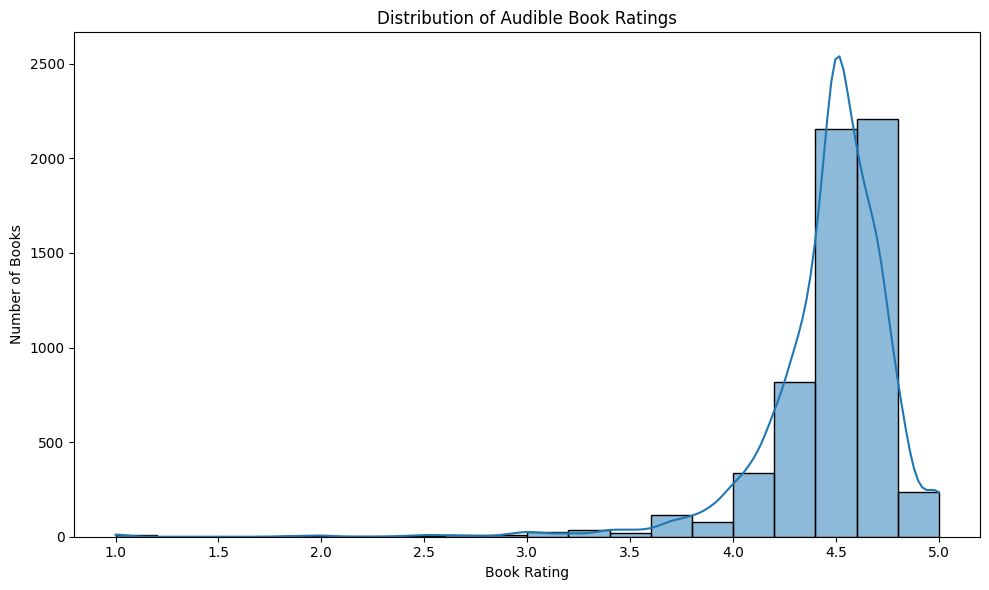

In [52]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="Rating",
    bins=20,
    kde=True
)

plt.title("Distribution of Audible Book Ratings")
plt.xlabel("Book Rating")
plt.ylabel("Number of Books")

plt.tight_layout()
plt.show()

**Key Observations:**

- The average rating across all books is approximately 4.46.
- The median rating is 4.5.
- Most books have ratings between 4.0 and 5.0.
- The rating distribution is concentrated toward higher ratings.
- The distribution is influenced by the replacement of 580 invalid ratings with the median rating of 4.5.

### 3.6 Publication Year Trends

**Project Question:**

Are there trends in publication years for popular books?

**Objective:**

To examine publication-year trends among popular books and identify changes in book popularity over time.

In [53]:
# Check available columns

print("Available Dataset Columns:")
print(df.columns.tolist())

# Find possible publication year or date columns

year_columns = [
    col for col in df.columns
    if "year" in col.lower() or "date" in col.lower()
]

print("\nPossible Publication Year Columns:")
print(year_columns)

Available Dataset Columns:
['Book Name', 'Author', 'Rating', 'Number of Reviews', 'Price', 'Description', 'Listening Time', 'Ranks and Genre', 'Genre', 'Listening_Time_Minutes']

Possible Publication Year Columns:
[]


#### 3.6.1 Dataset Limitation

**Observation:**

The cleaned Audible dataset does not contain a publication-year or publication-date column. Therefore, publication-year trends for popular books cannot be analyzed using the available data.

**Conclusion:**

Publication-year analysis is not possible with the provided datasets. Additional publication-date information would be required to perform this analysis.

### 3.7 Relationship Between Ratings and Number of Reviews

**Project Question:**

How do ratings vary between books with different review counts?

**Objective:**

To analyze the relationship between the number of customer reviews and book ratings and understand how ratings vary across books with different levels of review activity.

In [54]:
# Analyze the relationship between ratings and review counts

print("Review Count Statistics:")
display(df["Number of Reviews"].describe())

print("\nAverage Rating by Review Count:")

# Divide books into review-count groups
df["Review_Group"] = pd.cut(
    df["Number of Reviews"],
    bins=[-1, 100, 500, 1000, float("inf")],
    labels=["0–100", "101–500", "501–1000", "Above 1000"]
)

review_rating = (
    df.groupby("Review_Group", observed=False)
    .agg(
        Average_Rating=("Rating", "mean"),
        Number_of_Books=("Book Name", "count")
    )
    .reset_index()
)

display(review_rating.round(2))

Review Count Statistics:


count     6063.000000
mean       866.547254
std       2403.248628
min          1.000000
25%         78.000000
50%        239.000000
75%        664.500000
max      70122.000000
Name: Number of Reviews, dtype: float64


Average Rating by Review Count:


,Review_Group,Average_Rating,Number_of_Books
0,0–100,4.35,1760
1,101–500,4.49,2457
2,501–1000,4.53,730
3,Above 1000,4.53,1116


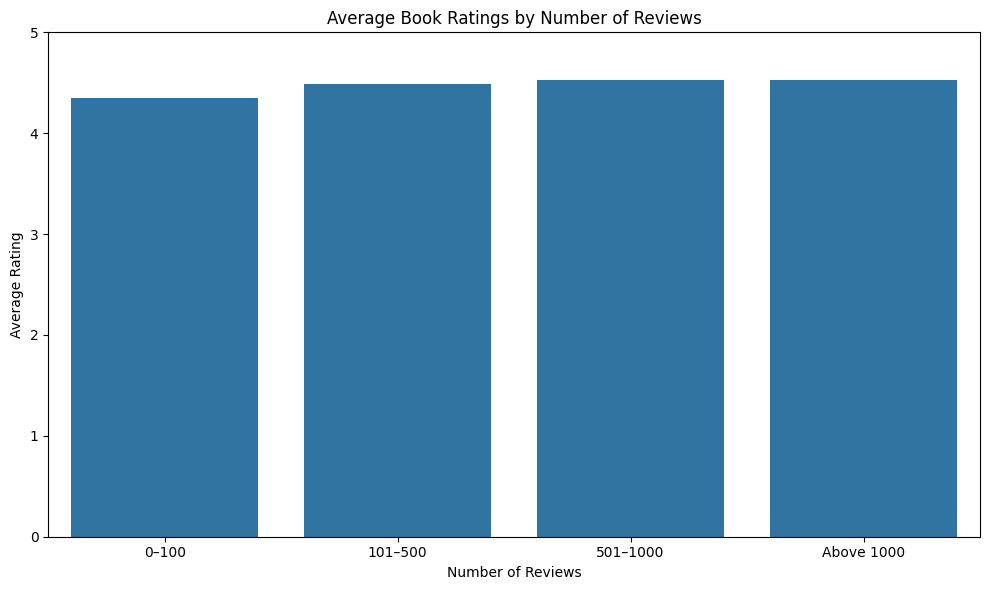

In [55]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=review_rating,
    x="Review_Group",
    y="Average_Rating"
)

plt.title("Average Book Ratings by Number of Reviews")
plt.xlabel("Number of Reviews")
plt.ylabel("Average Rating")
plt.ylim(0, 5)

plt.tight_layout()
plt.show()

**Key Observations:**

- Books with 0–100 reviews have an average rating of 4.35.
- Books with 101–500 reviews have an average rating of 4.49.
- Books with 501–1000 reviews have an average rating of 4.53.
- Books with more than 1000 reviews have an average rating of 4.53.
- Books with higher review counts show slightly higher average ratings.
- The difference between the highest and lowest group averages is 0.18.

**Note:** Missing review counts were filled with the median during data cleaning. Therefore, the review groups may be influenced by imputed values.

### 3.8 Book Similarity Analysis Using Descriptions

**Project Question:**

Which books frequently clustered together based on descriptions?

**Objective:**

To identify books with similar descriptions by converting textual descriptions into numerical features using NLP techniques. These features will later be used for clustering similar books.

In [56]:
import re

# Function to clean book descriptions
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()


# Clean the descriptions
df["Cleaned_Description"] = df["Description"].apply(clean_text)

# Identify descriptions that are unavailable
valid_descriptions = df[
    df["Description"].str.lower() != "description not available"
].copy()

print("Total Books:", len(df))
print("Books with Available Descriptions:", len(valid_descriptions))
print("Books with Unavailable Descriptions:", 
      len(df) - len(valid_descriptions))

print("\nSample Cleaned Descriptions:")
display(
    valid_descriptions[
        ["Book Name", "Description", "Cleaned_Description"]
    ].head()
)

Total Books: 6063
Books with Available Descriptions: 2417
Books with Unavailable Descriptions: 3646

Sample Cleaned Descriptions:


,Book Name,Description,Cleaned_Description
1,#Girlboss,"Penguin presents the unabridged downloadable, audiobook edition of #Girlboss by Sophia Amoruso, read by Sarah Jes Austell. The first thing Sophia Amoruso sold online wasn't fashion. It was a stolen book. At age 17 she was a dumpster-diving, shoplifting anarchist. By 29 she was the founder and CEO of Nasty Gal, a $100 million-plus fashion empire.",penguin presents the unabridged downloadable audiobook edition of girlboss by sophia amoruso read by sarah jes austell the first thing sophia amoruso sold online wasn t fashion it was a stolen book at age she was a dumpster diving shoplifting anarchist by she was the founder and ceo of nasty gal a million plus fashion empire
4,10 Essential Pieces Of Literature,This Audiobook contains the following works:,this audiobook contains the following works
5,10 Essential Success Mantras From The Bhagavad Gita (Rupa Quick Reads),"For thousands of years, the Bhagavad Gita has inspired millions of saints, leaders, scientists, philosophers and ordinary people around the world. In this quick read, Vimla Patil draws valuable success mantras from the philosophical text that are sure to take your life to the next level.",for thousands of years the bhagavad gita has inspired millions of saints leaders scientists philosophers and ordinary people around the world in this quick read vimla patil draws valuable success mantras from the philosophical text that are sure to take your life to the next level
7,10 Masterpieces You Have To Read Before You Die 1,This Audiobook contains the following works :,this audiobook contains the following works
8,10 Minutes 38 Seconds In This Strange World,Shortlisted for the Booker Prize 2019,shortlisted for the booker prize


In [57]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize TF-IDF vectorizer
tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=5000,
    min_df=2
)

# Convert cleaned descriptions into numerical features
tfidf_matrix = tfidf.fit_transform(
    valid_descriptions["Cleaned_Description"]
)

# Display TF-IDF results
print("TF-IDF Matrix Shape:", tfidf_matrix.shape)

print("\nTotal Books Analyzed:", tfidf_matrix.shape[0])
print("Total Unique Features:", tfidf_matrix.shape[1])

# Display sample feature names
print("\nSample TF-IDF Features:")
print(tfidf.get_feature_names_out()[:20])

TF-IDF Matrix Shape: (2417, 5000)

Total Books Analyzed: 2417
Total Unique Features: 5000

Sample TF-IDF Features:
['abandoned' 'abandoning' 'abandonment' 'abdul' 'abilities' 'ability'
 'able' 'abound' 'abraham' 'abridged' 'abrupt' 'absence' 'absolute'
 'absolutely' 'abuse' 'academic' 'academy' 'accelerate' 'accelerating'
 'accept']


In [58]:
from sklearn.cluster import KMeans

# Initialize K-Means model
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

# Train the model and assign clusters
valid_descriptions["Cluster"] = kmeans.fit_predict(tfidf_matrix)

# Display cluster assignments
print("K-Means Clustering Completed!")

print("\nNumber of Books in Each Cluster:")
display(valid_descriptions["Cluster"].value_counts().sort_index())

print("\nSample Clustered Books:")
display(
    valid_descriptions[
        ["Book Name", "Author", "Cluster"]
    ].head(15)
)

K-Means Clustering Completed!

Number of Books in Each Cluster:


Cluster
0    1438
1      87
2      81
3     111
4     700
Name: count, dtype: int64


Sample Clustered Books:


,Book Name,Author,Cluster
1,#Girlboss,Sophia Amoruso,3
4,10 Essential Pieces Of Literature,Khalil Gibran,0
5,10 Essential Success Mantras From The Bhagavad Gita (Rupa Quick Reads),Vimla Patil,4
7,10 Masterpieces You Have To Read Before You Die 1,Jane Austen,0
8,10 Minutes 38 Seconds In This Strange World,Elif Shafak,0
9,10 Skills For Effective Business Communication: Practical Strategies From The World'S Greatest Leaders,Jessica Higgins Jd Mba Bb,4
11,100 Baggers: Stocks That Return 100-To-1 And How To Find Them,Christopher W. Mayer,4
16,1000+ Little Things Happy Successful People Do Differently,Marc Chernoff,2
17,101 Amazing Facts About The Royal Family,Jack Goldstein,0
18,101 Amazing Facts About Trees,Jack Goldstein,0


In [59]:
# Display sample books from each cluster

for cluster in sorted(valid_descriptions["Cluster"].unique()):

    print(f"\n========== CLUSTER {cluster} ==========")

    cluster_books = valid_descriptions[
        valid_descriptions["Cluster"] == cluster
    ][["Book Name", "Author", "Genre"]].head(10)

    display(cluster_books)


========== CLUSTER 0 ==========


,Book Name,Author,Genre
4,10 Essential Pieces Of Literature,Khalil Gibran,Classic Literature | Classic Fiction
7,10 Masterpieces You Have To Read Before You Die 1,Jane Austen,"Caribbean & Latin American Literature | English, Irish, Scottish & Welsh Literature | Classic Literature"
8,10 Minutes 38 Seconds In This Strange World,Elif Shafak,Friendship Fiction | Women's Fiction | Political Fiction
17,101 Amazing Facts About The Royal Family,Jack Goldstein,Biographies of Royalty | Biographies & Autobiographies | Textbooks & Study Guides
18,101 Amazing Facts About Trees,Jack Goldstein,"Audiobooks on Flowers & Trees for Children | Botany & Plants | Children's Science, Nature & Technology"
19,101 Amazing Facts About William Shakespeare,Jack Goldstein,"Historical Biographies | Literary History & Criticism | Literary Theory, History & Criticism"
22,101 Best Indian Fables For Children,Stuti Gupta,"Fairy Tales, Folk Tales & Myths for Children | Literature & Fiction for Children | Children's Traditional Stories"
24,101 Fairy Tales Book,Dreamland Publications,Unknown
27,101 Panchatantra Stories,Om Books International,Contemporary Fiction | Fiction Short Stories | Short Stories
28,101 Panchtantra Stories,Dreamland Publications,"Fairy Tales, Folk Tales & Myths for Children | Literature & Fiction for Children | Children's Traditional Stories"



========== CLUSTER 1 ==========


,Book Name,Author,Genre
51,21 Lessons For The 21St Century,Yuval Noah Harari,Political Science History & Theory | United States Politics & Government | Political Theory
107,A Brief History Of Time: From Big Bang To Black Holes,Stephen Hawking,Physics | Cosmology | Astronomy
130,A Delayed Life: The True Story Of The Librarian Of Auschwitz,Dita Kraus,Unknown
194,A Room Of One'S Own: Penguin Classics,Virginia Woolf,Women's Studies | Society & Culture
408,Anxious People,Fredrik Backman,Humorous Fiction | Crime Fiction | Humour
478,Atomic Habits: An Easy And Proven Way To Build Good Habits And Break Bad Ones,James Clear,Psychology | Stress Management | Personal Success
509,Azadi: Freedom. Fascism. Fiction.,Arundhati Roy,Fascism | Communism & Socialism | Political Structure & Processes
542,Beach Read,Emily Henry,Romantic Comedy | Humorous Fiction | Romance
564,Behave,Robert M Sapolsky,Evolutionary Psychology | Evolution | History of Science
765,Camp Jupiter Classified: A Probatio'S Journal,Rick Riordan,Norse Fairy Tales for Children | Humor for Children | Fantasy & Magic for Children



========== CLUSTER 2 ==========


,Book Name,Author,Genre
16,1000+ Little Things Happy Successful People Do Differently,Marc Chernoff,Personal Success | Personal Development & Self-Help
40,"15 Secrets Successful People Know About Time Management: The Productivity Habits Of 7 Billionaires, 13 Olympic Athletes, 29 Straight-A Students, And 239 Entrepreneurs",Kevin Kruse,Time Management & Productivity | Business Careers | Personal Success
298,Airport,Arthur Hailey,Action Thriller Fiction | Suspense | Action & Adventure
331,All The Bright Places: Movie Tie-In Edition,Jennifer Niven,Fiction on Depression for Teens | Fiction on Suicide for Teens | Fiction on Mental Illness for Teens
511,Bad Blood,John Carreyrou,White Collar & Corporate True Crime | True Accounts | Business & Careers
539,Be Obsessed Or Be Average,Grant Cardone,Business Motivation & Self-Improvement | Business Careers | Analysis & Strategy
597,Between The World And Me,Ta-Nehisi Coates,Racism & Discrimination Studies | United States History | Biographies & Memoirs
623,Biomimicry: Innovation Inspired By Nature,Janine M. Benyus,Ecology | Biology | Economics
877,City Of Ghosts,Victoria Schwab,Paranormal & Supernatural Fantasy for Children | Scary Stories for Children | Action & Adventure for Children
878,City Of Girls,Elizabeth Gilbert,Historical Fiction



========== CLUSTER 3 ==========


,Book Name,Author,Genre
1,#Girlboss,Sophia Amoruso,Unknown
168,A Long Petal Of The Sea,Isabel Allende,Latino American Literature | World War II Historical Fiction | War & Military Fiction
172,A Monk'S Guide To A Clean House And Mind,Shoukei Matsumoto,Cleaning & Organising | Zen Buddhism | Meditation
185,A Political History Of The World: Three Thousand Years Of War And Peace (A Pelican Book),Jonathan Holslag,International Relations | World History | Military History
202,A Short History Of Nearly Everything,William Roberts,Unknown
306,Alchemy: The Surprising Power Of Ideas That Don'T Make Sense,Rory Sutherland,Marketing | Psychology | Analysis & Strategy
350,American Kingpin: The Epic Hunt For The Criminal Mastermind Behind The Silk Road Drugs Empire,Nick Bilton,Organised Crime | True Accounts | Society & Social Sciences
419,Ardennes 1944: Hitler'S Last Gamble,Antony Beevor,World War II History | European History
427,"Around The World In 80 Trains: A 45,000-Mile Adventure",Monisha Rajesh,Railroad Engineering | Railroad Travel | Asia Travel & Tourism
543,Beartown,Fredrik Backman,Small Town & Rural Fiction | Sports Fiction | Crime Thrillers



========== CLUSTER 4 ==========


,Book Name,Author,Genre
5,10 Essential Success Mantras From The Bhagavad Gita (Rupa Quick Reads),Vimla Patil,Hinduism | Forecasting & Strategic Planning | Leadership
9,10 Skills For Effective Business Communication: Practical Strategies From The World'S Greatest Leaders,Jessica Higgins Jd Mba Bb,Unknown
11,100 Baggers: Stocks That Return 100-To-1 And How To Find Them,Christopher W. Mayer,Money & Finance | Business & Economics
34,13 Kaam Jo Samajhdar Log Nahi Karte [13 Commonwealth Games],Amy Morin,Psychology | Textbooks & Study Guides
35,13 Steps To Bloody Good Luck,Ashwin Sanghi,Unknown
36,13 Steps To Bloody Good Wealth,Ashwin Sanghi,Indian Literature | Personal Finance | Personal Success
38,"13 Things Mentally Strong People Don'T Do: Take Back Your Power, Embrace Change, Face Your Fears, And Train Your Brain For Happiness And Success",Amy Morin,Business Motivation & Self-Improvement | Personal Success | Analysis & Strategy
41,168 Hours: You Have More Time Than You Think,Laura Vanderkam,Time Management | Time Management & Productivity | Personal Success
59,"30 Days - Change Your Habits, Change Your Life: A Couple Of Simple Steps Every Day To Create The Life You Want",Marc Reklau,Time Management & Productivity | Self-Esteem | Analysis & Strategy
77,"5-Minute Selling: The Proven, Simple System That Can Double Your Sales...Even When You Don'T Have Time",Alex Goldfayn,Unknown


In [60]:
# Get feature names from TF-IDF
terms = tfidf.get_feature_names_out()

# Get cluster centers
centers = kmeans.cluster_centers_

# Display top 10 important words in each cluster
for cluster_num in range(5):

    print(f"\n========== CLUSTER {cluster_num} ==========")

    # Find the indices of the top 10 words
    top_indices = centers[cluster_num].argsort()[-10:][::-1]

    # Display the corresponding words
    top_words = [terms[i] for i in top_indices]

    print("Important Words:", ", ".join(top_words))


========== CLUSTER 0 ==========
Important Words: world, story, stories, book, life, best, india, years, time, history

========== CLUSTER 1 ==========
Important Words: brought, penguin, zig, zero, zen, accompanying, written, academic, academy, zone

========== CLUSTER 2 ==========
Important Words: york, times, best, new, seller, selling, author, number, sunday, comes

========== CLUSTER 3 ==========
Important Words: presents, edition, audiobook, read, penguin, random, house, downloadable, unabridged, written

========== CLUSTER 4 ==========
Important Words: life, business, book, people, way, learn, work, make, guide, success


In [61]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# Add common promotional and audiobook-related words
custom_stop_words = list(ENGLISH_STOP_WORDS) + [
    "book", "books", "audiobook", "audiobooks",
    "edition", "read", "written", "presents",
    "penguin", "downloadable", "unabridged",
    "random", "house", "brought", "accompanying",
    "new", "york", "times", "best", "seller",
    "selling", "author", "number", "comes",
    "academic", "academy", "zero", "zig",
    "zen", "zone"
]

# Recreate TF-IDF features with custom stop words
tfidf = TfidfVectorizer(
    stop_words=custom_stop_words,
    max_features=5000,
    min_df=2
)

tfidf_matrix = tfidf.fit_transform(
    valid_descriptions["Cleaned_Description"]
)

print("Updated TF-IDF Matrix Shape:", tfidf_matrix.shape)
print("Promotional words removed successfully!")

Updated TF-IDF Matrix Shape: (2417, 5000)
Promotional words removed successfully!


In [62]:
# Apply K-Means on improved TF-IDF features

kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

valid_descriptions["Cluster"] = kmeans.fit_predict(tfidf_matrix)

print("Updated K-Means Clustering Completed!")

print("\nNumber of Books in Each Cluster:")
display(
    valid_descriptions["Cluster"]
    .value_counts()
    .sort_index()
)

Updated K-Means Clustering Completed!

Number of Books in Each Cluster:


Cluster
0      46
1    1463
2     323
3     260
4     325
Name: count, dtype: int64

In [63]:
# Get updated TF-IDF feature names
terms = tfidf.get_feature_names_out()

# Get updated cluster centers
centers = kmeans.cluster_centers_

for cluster_num in range(5):

    print(f"\n========== CLUSTER {cluster_num} ==========")

    top_indices = centers[cluster_num].argsort()[-10:][::-1]

    top_words = [terms[i] for i in top_indices]

    print("Important Words:", ", ".join(top_words))


========== CLUSTER 0 ==========
Important Words: winner, award, audie, prize, finalist, business, nominee, fiction, year, awards

========== CLUSTER 1 ==========
Important Words: years, story, series, business, like, year, guide, power, puffin, don

========== CLUSTER 2 ==========
Important Words: people, stories, great, novel, collection, english, story, tales, short, learn

========== CLUSTER 3 ==========
Important Words: world, war, history, business, way, years, india, modern, life, man

========== CLUSTER 4 ==========
Important Words: life, time, work, love, way, right, make, change, want, day


In [64]:
# Display sample books from each cluster

for cluster in sorted(valid_descriptions["Cluster"].unique()):

    print(f"\n========== CLUSTER {cluster} ==========")

    display(
        valid_descriptions[
            valid_descriptions["Cluster"] == cluster
        ][["Book Name", "Author", "Genre"]].head(10)
    )


========== CLUSTER 0 ==========


,Book Name,Author,Genre
578,Beloved,Toni Morrison,African American Literature | Coming of Age Fiction | Historical Fiction
597,Between The World And Me,Ta-Nehisi Coates,Racism & Discrimination Studies | United States History | Biographies & Memoirs
640,Bleak House: The Dickens Collection: An Audible Exclusive Series,Charles Dickens,Classic Literature | Classic Fiction
867,Cilka'S Journey: The Sequel To The Tattooist Of Auschwitz,Heather Morris,Unknown
1208,Dreamers: How Young Indians Are Changing Their World,Snigdha Poonam,Unknown
1272,Em And The Big Hoom,Jerry Pinto,Contemporary Fiction | Family Life Fiction | Literary Fiction
1367,Evil Eye,Madhuri Shekar,Drama & Plays | United States Literature | Plays
1481,Flights,Olga Tokarczuk,Literary Fiction | Contemporary Fiction
1513,Frankenstein,Mary Shelley,Horror Fiction | Classic Literature | Horror
1644,Good Omens: The Bbc Radio 4 Dramatisation,Terry Pratchett,Fantasy



========== CLUSTER 1 ==========


,Book Name,Author,Genre
1,#Girlboss,Sophia Amoruso,Unknown
4,10 Essential Pieces Of Literature,Khalil Gibran,Classic Literature | Classic Fiction
7,10 Masterpieces You Have To Read Before You Die 1,Jane Austen,"Caribbean & Latin American Literature | English, Irish, Scottish & Welsh Literature | Classic Literature"
8,10 Minutes 38 Seconds In This Strange World,Elif Shafak,Friendship Fiction | Women's Fiction | Political Fiction
11,100 Baggers: Stocks That Return 100-To-1 And How To Find Them,Christopher W. Mayer,Money & Finance | Business & Economics
16,1000+ Little Things Happy Successful People Do Differently,Marc Chernoff,Personal Success | Personal Development & Self-Help
17,101 Amazing Facts About The Royal Family,Jack Goldstein,Biographies of Royalty | Biographies & Autobiographies | Textbooks & Study Guides
19,101 Amazing Facts About William Shakespeare,Jack Goldstein,"Historical Biographies | Literary History & Criticism | Literary Theory, History & Criticism"
22,101 Best Indian Fables For Children,Stuti Gupta,"Fairy Tales, Folk Tales & Myths for Children | Literature & Fiction for Children | Children's Traditional Stories"
36,13 Steps To Bloody Good Wealth,Ashwin Sanghi,Indian Literature | Personal Finance | Personal Success



========== CLUSTER 2 ==========


,Book Name,Author,Genre
24,101 Fairy Tales Book,Dreamland Publications,Unknown
27,101 Panchatantra Stories,Om Books International,Contemporary Fiction | Fiction Short Stories | Short Stories
28,101 Panchtantra Stories,Dreamland Publications,"Fairy Tales, Folk Tales & Myths for Children | Literature & Fiction for Children | Children's Traditional Stories"
35,13 Steps To Bloody Good Luck,Ashwin Sanghi,Unknown
59,"30 Days - Change Your Habits, Change Your Life: A Couple Of Simple Steps Every Day To Create The Life You Want",Marc Reklau,Time Management & Productivity | Self-Esteem | Analysis & Strategy
66,365 Jataka Tales,Om Books International,"Literary Criticism for Children | Fairy Tales, Folk Tales & Myths for Children | Children's Traditional Stories"
67,365 Panchatantra Stories,Adil Mukesh,"Literary Criticism for Children | Fairy Tales, Folk Tales & Myths for Children | Children's Traditional Stories"
69,365 Tales Of Indian Mythology,Om Books International,Literary Criticism for Children | Children's Traditional Stories
79,50 Greatest Short Stories,Terry O'Brien - Editor,Literature Anthologies | Anthologies | Short Stories
90,"67 Hot Explicit Erotic Sex Stories: Swingers, Bdsm, Spanking, Bisexual, Paranormal Threesomes, Bbw Erotica, Lesbian First Time, Medical, Gangbangs And Much More...",Ashley Winters,Erotic Fiction



========== CLUSTER 3 ==========


,Book Name,Author,Genre
5,10 Essential Success Mantras From The Bhagavad Gita (Rupa Quick Reads),Vimla Patil,Hinduism | Forecasting & Strategic Planning | Leadership
9,10 Skills For Effective Business Communication: Practical Strategies From The World'S Greatest Leaders,Jessica Higgins Jd Mba Bb,Unknown
18,101 Amazing Facts About Trees,Jack Goldstein,"Audiobooks on Flowers & Trees for Children | Botany & Plants | Children's Science, Nature & Technology"
43,1984,George Orwell,Dystopian Science Fiction | Political Fiction | Literary Fiction
46,2 States: The Story Of My Marriage,Chetan Bhagat,Indian Literature | Romance | Anthologies
58,281 And Beyond,Vvs Laxman,Cricket | Sports Biographies
68,365 Stories From Around The World,Om Books International,"Literary Criticism for Children | Fairy Tales, Folk Tales & Myths for Children | Children's Traditional Stories"
94,7 Secrets Of Vishnu: The Hindu Trinity Series,Devdutt Pattanaik,Indian Literature | Hinduism | Buddhism
101,A Better India: A Better World,Narayan Murthy,Poverty & Homelessness Studies | Literary Essays | Politics & Government
118,A Concise History Of Modern India,Barbara Metcalf,Indian History | Asian History



========== CLUSTER 4 ==========


,Book Name,Author,Genre
29,101 Power Thoughts,Louise L. Hay,Unknown
34,13 Kaam Jo Samajhdar Log Nahi Karte [13 Commonwealth Games],Amy Morin,Psychology | Textbooks & Study Guides
41,168 Hours: You Have More Time Than You Think,Laura Vanderkam,Time Management | Time Management & Productivity | Personal Success
77,"5-Minute Selling: The Proven, Simple System That Can Double Your Sales...Even When You Don'T Have Time",Alex Goldfayn,Unknown
91,"7 Mindsets For Success, Happiness And Fulfilment",Swami Mukundananda,Spiritualism | New Thought Spirituality | Personal Success
108,A Briefer History Of Time,Stephen Hawking,Cosmology | Astronomy | Physics
120,A Course In Weight Loss: 21 Spiritual Lessons For Surrendering Your Weight Forever,Marianne Williamson,Weight Loss Diets | Self-Esteem | Middle Eastern History
131,A Dog'S Purpose: A Novel For Humans,W. Bruce Cameron,"Animal Fiction | Movie, TV & Video Game Tie-In Fiction | Humorous Fiction"
163,"A Life Worth Breathing: A Yoga Master'S Handbook Of Strength, Grace, And Healing",Max Strom,Unknown
218,A Thing Beyond Forever: The Reward For Every True Love Is Not Love…,Novoneel Chakraborty,Contemporary Fiction | Contemporary Romance | Literary Fiction


#### 3.8.1 Cluster Analysis – Observations

**Observations:**

1. The K-Means algorithm grouped 2,417 books with available descriptions into five clusters.
2. Cluster 0 contains several award-winning and literary works.
3. Cluster 2 includes many story collections, fairy tales, and traditional stories.
4. Cluster 3 contains books related to history, Indian literature, mythology, and other general topics.
5. Cluster 4 shows similarities among books related to personal development, productivity, and life topics.
6. Cluster 1 contains the largest number of books (1,463), indicating that several descriptions share common textual features.
7. Some clusters contain books from different genres because clustering is based on description similarity rather than predefined genre labels.

**Conclusion:**

TF-IDF successfully converted book descriptions into numerical features, and K-Means grouped books based on similarities in their textual content. Removing promotional words helped make the important cluster terms more meaningful. However, some clusters still contain mixed topics, so the results should be treated as exploratory groups rather than perfectly separated categories.

These clusters can be used as an additional feature for developing book recommendation systems.

### 3.9 Genre Similarity Analysis

**Project Question:**
How does genre similarity affect book recommendations?

**Objective:**
To examine how books sharing similar genres can be identified and used to recommend related books to users.

In [65]:
# Prepare individual genres for similarity analysis

genre_data = df[["Book Name", "Author", "Genre"]].copy()

genre_data["Genre_List"] = (
    genre_data["Genre"]
    .fillna("Unknown")
    .str.split(" | ", regex=False)
)

# Remove unknown and empty genre labels
genre_data["Genre_List"] = genre_data["Genre_List"].apply(
    lambda genres: [
        genre.strip()
        for genre in genres
        if genre.strip() and genre.strip() != "Unknown"
    ]
)

# Keep books with at least one known genre
genre_data = genre_data[
    genre_data["Genre_List"].apply(len) > 0
].copy()

print("Total books with known genres:", len(genre_data))

display(genre_data[["Book Name", "Author", "Genre_List"]].head(10))

Total books with known genres: 1997


,Book Name,Author,Genre_List
4,10 Essential Pieces Of Literature,Khalil Gibran,"[Classic Literature, Classic Fiction]"
5,10 Essential Success Mantras From The Bhagavad Gita (Rupa Quick Reads),Vimla Patil,"[Hinduism, Forecasting & Strategic Planning, Leadership]"
7,10 Masterpieces You Have To Read Before You Die 1,Jane Austen,"[Caribbean & Latin American Literature, English, Irish, Scottish & Welsh Literature, Classic Literature]"
8,10 Minutes 38 Seconds In This Strange World,Elif Shafak,"[Friendship Fiction, Women's Fiction, Political Fiction]"
11,100 Baggers: Stocks That Return 100-To-1 And How To Find Them,Christopher W. Mayer,"[Money & Finance, Business & Economics]"
16,1000+ Little Things Happy Successful People Do Differently,Marc Chernoff,"[Personal Success, Personal Development & Self-Help]"
17,101 Amazing Facts About The Royal Family,Jack Goldstein,"[Biographies of Royalty, Biographies & Autobiographies, Textbooks & Study Guides]"
18,101 Amazing Facts About Trees,Jack Goldstein,"[Audiobooks on Flowers & Trees for Children, Botany & Plants, Children's Science, Nature & Technology]"
19,101 Amazing Facts About William Shakespeare,Jack Goldstein,"[Historical Biographies, Literary History & Criticism, Literary Theory, History & Criticism]"
22,101 Best Indian Fables For Children,Stuti Gupta,"[Fairy Tales, Folk Tales & Myths for Children, Literature & Fiction for Children, Children's Traditional Stories]"


In [66]:
# Convert genre lists into numerical features

from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.metrics.pairwise import cosine_similarity

mlb = MultiLabelBinarizer()

genre_matrix = mlb.fit_transform(genre_data["Genre_List"])

print("Genre Matrix Shape:", genre_matrix.shape)
print("Total Unique Genres:", len(mlb.classes_))

# Calculate cosine similarity between books
genre_similarity = cosine_similarity(genre_matrix)

print("Genre Similarity Matrix Shape:", genre_similarity.shape)

Genre Matrix Shape: (1997, 865)
Total Unique Genres: 865
Genre Similarity Matrix Shape: (1997, 1997)


In [67]:
# Select a sample book
book_index = 0

# Get similarity scores for the selected book
similarity_scores = genre_similarity[book_index]

# Get the indices of the five most similar books
similar_indices = similarity_scores.argsort()[::-1][1:6]

# Display recommendations
recommendations = genre_data.iloc[similar_indices][
    ["Book Name", "Author", "Genre_List"]
].copy()

recommendations["Similarity Score"] = similarity_scores[similar_indices]

print("Selected Book:")
display(
    genre_data.iloc[[book_index]][
        ["Book Name", "Author", "Genre_List"]
    ]
)

print("\nTop 5 Genre-Similar Books:")
display(recommendations.reset_index(drop=True))

Selected Book:


,Book Name,Author,Genre_List
4,10 Essential Pieces Of Literature,Khalil Gibran,"[Classic Literature, Classic Fiction]"



Top 5 Genre-Similar Books:


,Book Name,Author,Genre_List,Similarity Score
0,Gone With The Wind,Margaret Mitchell,"[Classic Literature, Classic Fiction]",1.0
1,Jane Eyre,Charlotte Bronte,"[Classic Literature, Classic Fiction]",1.0
2,The Idiot,Fyodor Dostoyevsky,"[Classic Literature, Classic Fiction]",1.0
3,Aavarana: The Veil,S. L. Bhyrappa,"[Classic Literature, Classic Fiction]",1.0
4,The Great Short Story Collection: 66 Classic Gems Of The Short Story Genre,Barry Pain,"[Classic Literature, Classic Fiction]",1.0


#### 3.9.1 Genre Similarity Analysis – Observations

**Observations:**

1. A total of 1,997 books with known genres were considered for genre similarity analysis.
2. The dataset contained 865 unique genre labels.
3. MultiLabelBinarizer converted book genres into numerical features.
4. Cosine similarity was used to measure genre similarity between books.
5. The selected book, "10 Essential Pieces of Literature", belongs to Classic Literature and Classic Fiction.
6. The five recommended books received similarity scores of 1.0 because they share the same genre labels as the selected book.

**Conclusion:**

Genre similarity plays an important role in book recommendations. Books that share similar genres can be recommended to users based on their reading interests. The cosine similarity technique successfully identified books with matching genres.

This approach can be integrated into the content-based recommendation system to suggest books with similar genres.

### 3.10 Effect of Author Popularity on Book Ratings

**Project Question:**
What is the effect of author popularity on book ratings?

**Objective:**
To analyze the relationship between author popularity and average book ratings using the number of books and customer reviews as indicators of popularity.

In [68]:
# Analyze author popularity and book ratings

author_analysis = (
    df.groupby("Author")
    .agg(
        Total_Books=("Book Name", "count"),
        Average_Rating=("Rating", "mean"),
        Total_Reviews=("Number of Reviews", "sum")
    )
    .reset_index()
)

# Consider authors with at least 3 books
author_analysis = author_analysis[
    author_analysis["Total_Books"] >= 3
].copy()

# Display the most popular authors by total reviews
top_popular_authors = author_analysis.sort_values(
    by="Total_Reviews",
    ascending=False
).head(10)

print("Top 10 Authors by Total Review Count:")
display(top_popular_authors.round(2))

Top 10 Authors by Total Review Count:


,Author,Total_Books,Average_Rating,Total_Reviews
1028,E. L. James,4,4.15,81191.0
2096,Lee Child,15,4.49,69873.0
1637,Jeff Kinney,16,4.61,68547.0
2974,Rick Riordan,26,4.68,67515.0
1517,J.K. Rowling,10,4.66,62329.0
3498,Suzanne Collins,4,4.62,61394.0
1769,John Green,5,4.42,60963.0
718,Dan Brown,6,4.40,53859.0
783,David Baldacci,12,4.51,47656.0
3219,Sarah J. Maas,10,4.72,43807.0


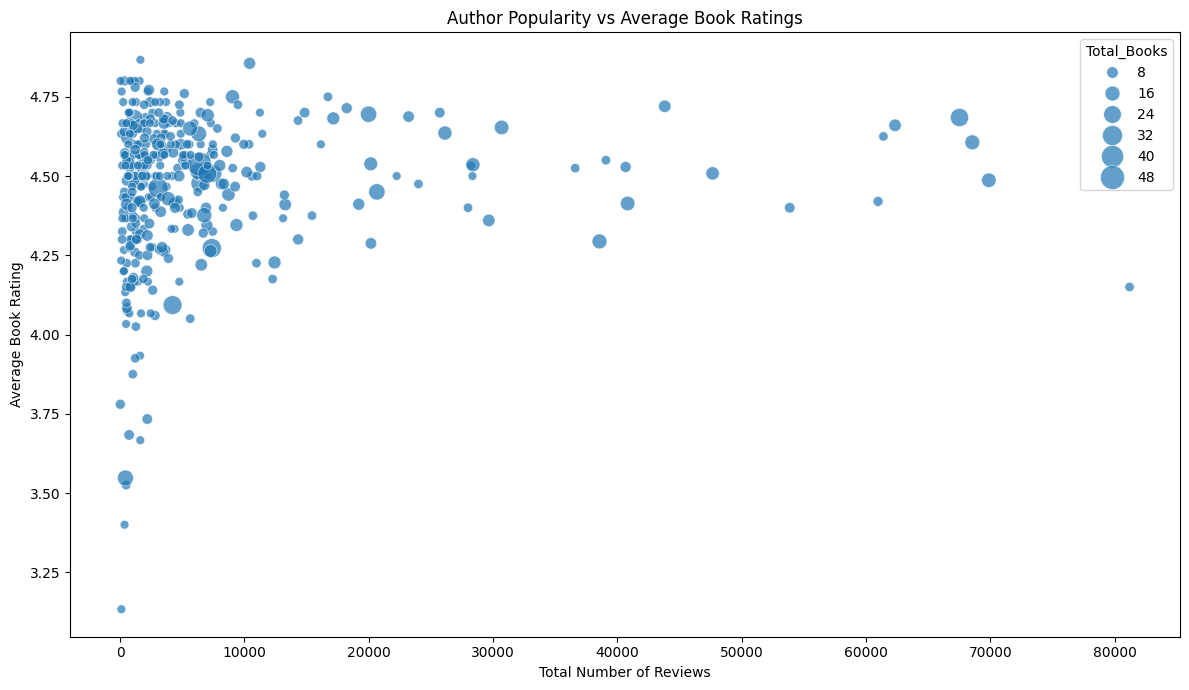

In [69]:
# Visualize author popularity and average ratings

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=author_analysis,
    x="Total_Reviews",
    y="Average_Rating",
    size="Total_Books",
    sizes=(40, 300),
    alpha=0.7
)

plt.title("Author Popularity vs Average Book Ratings")
plt.xlabel("Total Number of Reviews")
plt.ylabel("Average Book Rating")
plt.tight_layout()
plt.show()

In [70]:
# Calculate correlation between popularity and average ratings

correlation = author_analysis[
    ["Total_Reviews", "Average_Rating"]
].corr().iloc[0, 1]

print("Correlation between Author Popularity and Average Rating:",
      round(correlation, 3))

Correlation between Author Popularity and Average Rating: 0.091


#### 3.10.1 Author Popularity Analysis – Observations

**Observations:**

1. E. L. James has the highest total review count (81,191) among the top 10 authors analyzed.
2. Rick Riordan has the highest number of books (26) in the top 10.
3. Sarah J. Maas has the highest average rating (4.72) among these authors.
4. The correlation between total author reviews and average ratings is 0.091.
5. This indicates a very weak positive relationship between author popularity and average book ratings.

**Conclusion:**

The analysis shows that author popularity does not strongly influence average book ratings in this dataset. Authors with a higher number of customer reviews do not necessarily have higher average ratings.

Therefore, popularity and reader satisfaction should be considered separate factors when developing a book recommendation system.

### 3.11 Feature Combination Analysis for Book Recommendations

**Project Question:**
Which combination of features provides the most accurate recommendations?

**Objective:**
To compare book description features, genre features, and their combination to identify which approach provides the most relevant book recommendations.

In [71]:
# Prepare a common dataset for feature comparison

comparison_df = valid_descriptions[
    ["Book Name", "Author", "Cleaned_Description"]
].copy()

comparison_df["Genre_List"] = genre_data["Genre_List"].reindex(
    comparison_df.index
)

# Remove books without genre information
comparison_df = comparison_df.dropna(subset=["Genre_List"]).copy()

# Reset index
comparison_df = comparison_df.reset_index(drop=True)

print("Books available for feature comparison:", len(comparison_df))

display(
    comparison_df[
        ["Book Name", "Author", "Cleaned_Description", "Genre_List"]
    ].head()
)

Books available for feature comparison: 1937


,Book Name,Author,Cleaned_Description,Genre_List
0,10 Essential Pieces Of Literature,Khalil Gibran,this audiobook contains the following works,"[Classic Literature, Classic Fiction]"
1,10 Essential Success Mantras From The Bhagavad Gita (Rupa Quick Reads),Vimla Patil,for thousands of years the bhagavad gita has inspired millions of saints leaders scientists philosophers and ordinary people around the world in this quick read vimla patil draws valuable success mantras from the philosophical text that are sure to take your life to the next level,"[Hinduism, Forecasting & Strategic Planning, Leadership]"
2,10 Masterpieces You Have To Read Before You Die 1,Jane Austen,this audiobook contains the following works,"[Caribbean & Latin American Literature, English, Irish, Scottish & Welsh Literature, Classic Literature]"
3,10 Minutes 38 Seconds In This Strange World,Elif Shafak,shortlisted for the booker prize,"[Friendship Fiction, Women's Fiction, Political Fiction]"
4,100 Baggers: Stocks That Return 100-To-1 And How To Find Them,Christopher W. Mayer,this book is about baggers these are stocks that return for every invested that means a investment turns into million chris mayer can help you find them,"[Money & Finance, Business & Economics]"


In [72]:
# ==========================================
# CREATE THREE FEATURE REPRESENTATIONS
# ==========================================

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.metrics.pairwise import cosine_similarity
from scipy.sparse import hstack

# 1. Description-based TF-IDF features
description_vectorizer = TfidfVectorizer(
    stop_words=custom_stop_words,
    max_features=5000,
    min_df=2
)

description_matrix = description_vectorizer.fit_transform(
    comparison_df["Cleaned_Description"]
)

# 2. Genre-based features
genre_encoder = MultiLabelBinarizer()

genre_features = genre_encoder.fit_transform(
    comparison_df["Genre_List"]
)

# 3. Combined description and genre features
combined_matrix = hstack([
    description_matrix,
    genre_features * 2
]).tocsr()

print("Description Feature Shape:", description_matrix.shape)
print("Genre Feature Shape:", genre_features.shape)
print("Combined Feature Shape:", combined_matrix.shape)

Description Feature Shape: (1937, 5000)
Genre Feature Shape: (1937, 857)
Combined Feature Shape: (1937, 5857)


In [73]:
# ==========================================
# CALCULATE BOOK SIMILARITY
# ==========================================

# 1. Description-based similarity
description_similarity = cosine_similarity(
    description_matrix
)

# 2. Genre-based similarity
genre_similarity_comparison = cosine_similarity(
    genre_features
)

# 3. Combined feature similarity
combined_similarity = cosine_similarity(
    combined_matrix
)

print("Description Similarity Shape:", description_similarity.shape)
print("Genre Similarity Shape:", genre_similarity_comparison.shape)
print("Combined Similarity Shape:", combined_similarity.shape)

Description Similarity Shape: (1937, 1937)
Genre Similarity Shape: (1937, 1937)
Combined Similarity Shape: (1937, 1937)


In [74]:
# ==========================================
# COMPARE TOP 5 RECOMMENDATIONS
# ==========================================

# Select the first book
selected_index = 0

def get_top_recommendations(similarity_matrix, index, top_n=5):

    similarity_scores = similarity_matrix[index]

    # Exclude the selected book itself
    similar_indices = np.argsort(similarity_scores)[::-1]

    similar_indices = [
        i for i in similar_indices if i != index
    ][:top_n]

    recommendations = comparison_df.iloc[similar_indices][
        ["Book Name", "Author"]
    ].copy()

    recommendations["Similarity Score"] = [
        similarity_scores[i] for i in similar_indices
    ]

    return recommendations


print("Selected Book:")
print(comparison_df.iloc[selected_index]["Book Name"])

print("\n1. Description-Based Recommendations:")
display(
    get_top_recommendations(
        description_similarity, selected_index
    )
)

print("\n2. Genre-Based Recommendations:")
display(
    get_top_recommendations(
        genre_similarity_comparison, selected_index
    )
)

print("\n3. Combined-Feature Recommendations:")
display(
    get_top_recommendations(
        combined_similarity, selected_index
    )
)

Selected Book:
10 Essential Pieces Of Literature

1. Description-Based Recommendations:


,Book Name,Author,Similarity Score
2,10 Masterpieces You Have To Read Before You Die 1,Jane Austen,1.000000
34,50 Self-Help Classics To Guide You To Financial Freedom,Napoleon Hill,1.000000
181,"Bared To You: A Crossfire Novel, Book 1",Sylvia Day,0.237039
1159,Still Me,Jojo Moyes,0.217845
1547,"The Most Beloved Children’S Bedtime Stories: 15 Aesop’S Fables For Kids, The Three Little Pigs, Little Red Riding Hood, Goldilocks And The Three Bears, Snow White And The Seven Dwarfs And Many More",Joanna White,0.215900



2. Genre-Based Recommendations:


,Book Name,Author,Similarity Score
86,Aavarana: The Veil,S. L. Bhyrappa,1.0
407,Edgar Allan Poe - Complete Tales And Poems,Edgar Allan Poe,1.0
381,Don Quixote: Penguin Classics,Miguel Cervantes,1.0
493,"Fresh Floods: Ponniyin Selvan, Book 1",Kalki R. Krishnamurthy,1.0
214,Bleak House: The Dickens Collection: An Audible Exclusive Series,Charles Dickens,1.0



3. Combined-Feature Recommendations:


,Book Name,Author,Similarity Score
381,Don Quixote: Penguin Classics,Miguel Cervantes,0.942809
919,Notes From The Underground,Fyodor Dostoevsky,0.896684
493,"Fresh Floods: Ponniyin Selvan, Book 1",Kalki R. Krishnamurthy,0.888889
407,Edgar Allan Poe - Complete Tales And Poems,Edgar Allan Poe,0.888889
424,Endymion,John Keats,0.888889


#### 3.11.1 Feature Combination Analysis – Observations

**Observations:**

1. Three recommendation approaches were compared: description-based, genre-based, and combined-feature recommendations.
2. Description-based recommendations identified books with similar textual descriptions. However, some results were influenced by short or limited descriptions.
3. Genre-based recommendations identified books sharing the same genre labels, producing similarity scores of 1.0 for the selected book.
4. Combined-feature recommendations considered both description and genre information.
5. The combined approach produced similarity scores ranging from approximately 0.89 to 0.94 for the selected book.
6. Combining description and genre features provides additional information compared with using either feature independently.

**Conclusion:**

The analysis demonstrates that book descriptions and genre information can both contribute to content-based recommendations. Description-based recommendations capture textual similarities, while genre-based recommendations identify books belonging to similar categories.

The combined-feature approach considers both sources of information and provides a useful basis for developing the recommendation system.

However, actual recommendation accuracy cannot be established because the available dataset does not contain user preferences or ground-truth recommendation labels. Therefore, this comparison is based on cosine similarity scores and the relevance of the sample recommendations.

## 4. Scenario-Based Book Recommendations

### 4.1 Science Fiction Recommendations

**Scenario:**
A new user likes Science Fiction. Recommend the top five books based on this preference.

**Objective:**
To identify books belonging to the Science Fiction genre and recommend the five highest-rated books.

In [75]:
# Check available genres related to Science Fiction

science_fiction_genres = [
    genre for genre in mlb.classes_
    if "science fiction" in genre.lower()
]

print("Science Fiction Genres Found:")
print(science_fiction_genres)

Science Fiction Genres Found:
['Adventure Science Fiction', 'Alternate History Science Fiction', "Children's Science Fiction", 'Cyberpunk Science Fiction', 'Dystopian Science Fiction', 'First Contact Science Fiction', 'Hard Science Fiction', 'Post-Apocalyptic Science Fiction', 'Science Fiction', 'Science Fiction Anthologies & Short Stories', 'Science Fiction Dramatisations', 'Science Fiction Movie, TV & Video Game Tie-Ins', 'Science Fiction Romance for Teens', 'Science Fiction for Teens', 'Space Exploration Science Fiction', 'Space Opera Science Fiction', 'Time Travel Science Fiction', 'Time Travel Science Fiction for Children']


In [76]:
# ==========================================
# SCIENCE FICTION TOP 5 RECOMMENDATIONS
# ==========================================

# Select books containing any Science Fiction genre
science_fiction_books = genre_data[
    genre_data["Genre_List"].apply(
        lambda genres: any(
            "science fiction" in genre.lower()
            for genre in genres
        )
    )
].copy()

# Merge with ratings and review counts
science_fiction_books = science_fiction_books.merge(
    df[["Book Name", "Author", "Rating", "Number of Reviews"]],
    on=["Book Name", "Author"],
    how="left"
)

# Sort by rating, then review count
top_5_science_fiction = (
    science_fiction_books
    .sort_values(
        by=["Rating", "Number of Reviews"],
        ascending=[False, False]
    )
    .drop_duplicates(subset=["Book Name", "Author"])
    .head(5)
)

print("Total Science Fiction Books:", len(science_fiction_books))

print("\nTop 5 Science Fiction Recommendations:")
display(
    top_5_science_fiction[
        ["Book Name", "Author", "Rating", "Number of Reviews", "Genre"]
    ]
)

Total Science Fiction Books: 39

Top 5 Science Fiction Recommendations:


,Book Name,Author,Rating,Number of Reviews,Genre
17,Morning Star: Book Iii Of The Red Rising Trilogy,Pierce Brown,4.8,3016.0,Hard Science Fiction | Dystopian Science Fiction | Adventure Science Fiction
25,"So Long, Lollipops: The Free Until The End Of The World Novella",Sarah Lyons Fleming,4.8,174.0,Horror Fiction | Post-Apocalyptic Science Fiction
31,The Martian,Andy Weir,4.7,33293.0,Hard Science Fiction | Adventure Science Fiction | Suspense
15,Jurassic Park: A Novel,Michael Crichton,4.7,3259.0,"Science Fiction Movie, TV & Video Game Tie-Ins | Movie, TV & Video Game Tie-In Fiction | Adventure Science Fiction"
36,Thrawn (Star Wars),Timothy Zahn,4.7,2328.0,Space Opera Science Fiction | Adventure Science Fiction | Science Fiction


#### 4.1.1 Science Fiction Recommendations – Observations

**Observations:**

1. The dataset contains 39 books belonging to Science Fiction and its related subgenres.
2. Morning Star: Book III of the Red Rising Trilogy and So Long, Lollipops received the highest rating of 4.8.
3. The Martian received a rating of 4.7 and has the highest number of reviews among the five recommended books (33,293).
4. Jurassic Park and Thrawn also received ratings of 4.7.
5. The recommendations include different Science Fiction subgenres, such as Hard Science Fiction, Dystopian Science Fiction, Adventure Science Fiction, and Space Opera Science Fiction.

**Conclusion:**

The system successfully identified and recommended the top five Science Fiction books based on their ratings and review counts.

This demonstrates how genre preferences, ratings, and customer reviews can be used to generate personalized book recommendations for new users.

### 4.2 Thriller-Based Book Recommendations

**Scenario:**
A user has previously rated thriller books highly. Recommend similar books based on their genre preferences.

**Objective:**
To identify thriller books and recommend the highest-rated books using genre information, ratings, and customer reviews.

In [77]:
# ==========================================
# THRILLER BOOK RECOMMENDATIONS
# ==========================================

thriller_books = genre_data[
    genre_data["Genre_List"].apply(
        lambda genres: any(
            "thriller" in genre.lower()
            for genre in genres
        )
    )
].copy()

thriller_books = thriller_books.merge(
    df[["Book Name", "Author", "Rating", "Number of Reviews"]],
    on=["Book Name", "Author"],
    how="left"
)

top_5_thrillers = (
    thriller_books
    .sort_values(
        by=["Rating", "Number of Reviews"],
        ascending=[False, False]
    )
    .drop_duplicates(subset=["Book Name", "Author"])
    .head(5)
)

print("Total Thriller Books:", len(thriller_books))

print("\nTop 5 Thriller Recommendations:")
display(
    top_5_thrillers[
        ["Book Name", "Author", "Rating", "Number of Reviews", "Genre"]
    ]
)

Total Thriller Books: 117

Top 5 Thriller Recommendations:


,Book Name,Author,Rating,Number of Reviews,Genre
57,Sherlock Holmes: The Definitive Collection,Arthur Conan Doyle,5.0,6.0,"Private Investigator Mysteries | Crime, Thriller & Mystery"
13,Blasphemy: The Trial Of Danesh Masih,Osman Haneef,4.9,13.0,"Legal Thrillers | Crime, Thriller & Mystery"
103,Thunderhead: Arc Of A Scythe,Neal Shusterman,4.8,1451.0,Mystery & Detective Fiction for Teens | Thrillers & Suspense for Teens | Art for Teens
46,Nightshade,Anthony Horowitz,4.8,502.0,Thriller & Suspense Stories for Children | Action & Adventure Mysteries for Children | Mysteries for Children
79,The Harbinger Ii: The Return,Jonathan Cahn,4.8,317.0,Biblical Fiction | Christian Thriller & Suspense | Religious & Spiritual Fiction


#### 4.2.1 Thriller Recommendations – Observations

**Observations:**

1. The dataset contains 117 books belonging to thriller-related genres.
2. Sherlock Holmes: The Definitive Collection received the highest rating of 5.0, with 6 reviews.
3. Blasphemy: The Trial of Danesh Masih received a rating of 4.9, with 13 reviews.
4. Thunderhead: Arc of a Scythe, Nightshade, and The Harbinger II: The Return received ratings of 4.8.
5. Thunderhead has the highest review count among the five recommended books, with 1,451 reviews.
6. The recommendations include different categories such as Crime, Legal Thrillers, Mystery, and Christian Thriller.

**Conclusion:**

The system successfully identified thriller-related books and recommended the five highest-rated books.

Genre information, customer ratings, and review counts can help generate recommendations based on a user's reading preferences.

However, these recommendations are based on genre matching and book ratings rather than actual user reading history.

### 4.3 Hidden Gem Book Recommendations

**Scenario:**
A user wants to discover highly rated books that are less popular among readers.

**Objective:**
To identify hidden gems by selecting books with high ratings and relatively low numbers of customer reviews.

In [78]:
# ==========================================
# HIDDEN GEM BOOK RECOMMENDATIONS
# ==========================================

hidden_gems = df[
    (df["Rating"] >= 4.7) &
    (df["Number of Reviews"] <= 100)
].copy()

hidden_gems = (
    hidden_gems
    .sort_values(
        by=["Rating", "Number of Reviews"],
        ascending=[False, True]
    )
    .drop_duplicates(subset=["Book Name", "Author"])
)

print("Total Hidden Gem Books:", len(hidden_gems))

print("\nTop 10 Hidden Gem Recommendations:")

display(
    hidden_gems[
        ["Book Name", "Author", "Rating", "Number of Reviews", "Genre"]
    ].head(10)
)

Total Hidden Gem Books: 444

Top 10 Hidden Gem Recommendations:


,Book Name,Author,Rating,Number of Reviews,Genre
18,101 Amazing Facts About Trees,Jack Goldstein,5.0,1.0,"Audiobooks on Flowers & Trees for Children | Botany & Plants | Children's Science, Nature & Technology"
82,50 Self-Help Classics To Guide You To Financial Freedom,Napoleon Hill,5.0,1.0,Money Management | Personal Development & Self-Help
239,Aamool Kranti Ki Chunauti [Radical Revolution Is The Key Challenge],J. Krishnamurti,5.0,1.0,Unknown
626,Birth Of Ganesha,Shobha Viswanath,5.0,1.0,Unknown
670,Born To Run Barefoot?: Sorting Through The Myths And Facts Of Barefoot Running,Chas Gillespie,5.0,1.0,Unknown
718,"Buddha The First Quantum Physicist: Bridging 2500 Years, Buddha And Albert Einstein Speak The Same Language",Osho,5.0,1.0,Unknown
938,Constitutional Grounds For Presidential Impeachment,The Majority Staff Of The House Committee On The Judiciary -- 116Th Congress (1St Session),5.0,1.0,Unknown
1017,Dale Carnegie & Associates' Listen!: The Art Of Effective Communication,Dale Carnegie & Associates,5.0,1.0,Unknown
1139,Diktate - Hören - Schreiben - Korrigieren: Deutsch Üben,Werner Heidemann,5.0,1.0,German Language Learning | Language Learning & Teaching
1257,Eighty Days To Elsewhere,Kc Dyer,5.0,1.0,Unknown


#### 4.3.1 Hidden Gem Recommendations – Observations

**Observations:**

1. A total of 444 books were identified as potential hidden gems.
2. The selection criteria were a rating of 4.7 or higher and a maximum of 100 customer reviews.
3. Several books received a perfect rating of 5.0 with only one customer review.
4. Examples include 101 Amazing Facts About Trees, 50 Self-Help Classics to Guide You to Financial Freedom, and Birth of Ganesha.
5. The selected books belong to different categories, including self-help, science, language learning, and children's books.
6. Books with very few reviews may have limited evidence of overall reader satisfaction.

**Conclusion:**

The analysis successfully identified highly rated books with relatively low popularity.

These books can be presented as potential hidden gems to help readers discover less popular titles.

Considering both ratings and review counts provides a useful way to identify books that may deserve more attention. However, ratings based on very few reviews should be interpreted cautiously.

## 5. Recommendation System Development

### 5.1 Content-Based Filtering

**Objective:**

To develop a content-based recommendation system that suggests books similar to a user's selected book using book descriptions and genre information.

**Approach:**

The system uses TF-IDF features from book descriptions and genre-based features to calculate cosine similarity between books. Books with higher similarity scores are recommended to users.

In [79]:
# ==========================================
# CONTENT-BASED RECOMMENDATION SYSTEM
# ==========================================

def recommend_books(book_name, top_n=5):

    # Find the selected book
    matching_books = comparison_df[
        comparison_df["Book Name"].str.lower()
        == book_name.lower()
    ]

    if matching_books.empty:
        print("Book not found in the recommendation dataset.")
        return

    book_index = matching_books.index[0]

    # Get recommendations using combined similarity
    recommendations = get_top_recommendations(
        combined_similarity,
        book_index,
        top_n
    )

    print("Selected Book:", book_name)
    print("\nRecommended Books:")

    return recommendations


# Test the recommendation system
recommend_books("The Martian")

Selected Book: The Martian

Recommended Books:


,Book Name,Author,Similarity Score
854,Morning Star: Book Iii Of The Red Rising Trilogy,Pierce Brown,0.615385
263,Chanakya'S Chant,Ashwin Sanghi,0.369800
212,Blade Runner: Originally Published As Do Androids Dream Of Electric Sheep?,Philip K. Dick,0.323359
1803,"Tripwire: Jack Reacher, Book 3",Lee Child,0.320256
1037,Ready Player One,Ernest Cline,0.320256


#### 5.1.1 Content-Based Recommendation – Results and Observations

**Selected Book:** The Martian

**Observations:**

1. The content-based recommendation system successfully generated five recommendations.
2. Morning Star: Book III of the Red Rising Trilogy received the highest similarity score of 0.6154.
3. Chanakya's Chant received a similarity score of 0.3698.
4. Blade Runner received a similarity score of 0.3234.
5. Tripwire and Ready Player One received similarity scores of approximately 0.3203.
6. The system uses combined description and genre features to identify similar books.

**Conclusion:**

The content-based recommendation system successfully recommends books based on their description and genre features using cosine similarity.

The results demonstrate that book features can be used to identify potentially similar books without requiring user interaction history.

### 5.2 Clustering-Based Recommendations

**Objective:**

To recommend books by identifying other books belonging to the same K-Means cluster.

**Approach:**

Books with similar descriptions are grouped into clusters using the K-Means algorithm. When a user selects a book, the system identifies its cluster and recommends other books from that cluster.

In [81]:
# ==========================================
# IMPROVED CLUSTERING-BASED RECOMMENDATIONS
# ==========================================

def recommend_cluster_books(book_name, top_n=5):

    # Find the selected book
    matching_books = valid_descriptions[
        valid_descriptions["Book Name"].str.lower()
        == book_name.lower()
    ]

    if matching_books.empty:
        print("Book not found in clustering dataset.")
        return

    # Get the original index and corresponding matrix position
    selected_original_index = matching_books.index[0]
    selected_position = valid_descriptions.index.get_loc(
        selected_original_index
    )

    selected_cluster = valid_descriptions.loc[
        selected_original_index, "Cluster"
    ]

    # Get similarity scores using the TF-IDF matrix
    similarity_scores = cosine_similarity(
        tfidf_matrix[selected_position],
        tfidf_matrix
    ).flatten()

    # Select books belonging to the same cluster
    cluster_positions = np.where(
        valid_descriptions["Cluster"].values == selected_cluster
    )[0]

    # Exclude the selected book
    cluster_positions = cluster_positions[
        cluster_positions != selected_position
    ]

    # Sort books by similarity score
    ranked_positions = cluster_positions[
        np.argsort(similarity_scores[cluster_positions])[::-1]
    ][:top_n]

    recommendations = valid_descriptions.iloc[
        ranked_positions
    ][["Book Name", "Author", "Cluster"]].copy()

    recommendations["Similarity Score"] = similarity_scores[
        ranked_positions
    ]

    print("Selected Book:", book_name)
    print("Cluster:", selected_cluster)
    print("\nTop Recommendations from the Same Cluster:")

    return recommendations.reset_index(drop=True)


# Test the improved function
recommend_cluster_books("The Martian")

Selected Book: The Martian
Cluster: 1

Top Recommendations from the Same Cluster:


,Book Name,Author,Cluster,Similarity Score
0,Homegoing,Yaa Gyasi,1,0.284518
1,"Revenge Of The Invisible Boy: Goosebumps Slappyworld, Book 9",R.L. Stine,1,0.197665
2,God Of War,J. M. Barlog,1,0.182201
3,Choose Fi: Your Blueprint To Financial Independence,Chris Mamula,1,0.173321
4,Rust In Peace: The Inside Story Of The Megadeth Masterpiece,Dave Mustaine,1,0.166462


#### 5.2.1 Clustering-Based Recommendation – Results and Observations

**Selected Book:** The Martian

**Observations:**

1. The selected book belongs to Cluster 1.
2. The system identified other books belonging to the same cluster.
3. Homegoing received the highest similarity score of 0.2845 among the five recommendations.
4. Revenge of the Invisible Boy received a similarity score of 0.1977.
5. The remaining recommendations had similarity scores between approximately 0.166 and 0.182.
6. Some recommended books belong to different subject areas, indicating that the clusters do not always represent clearly defined topics.

**Conclusion:**

The clustering-based recommendation system successfully identifies books belonging to the same K-Means cluster and ranks them using cosine similarity.

However, the recommendations contain some unrelated books because the existing clusters have mixed topics. Therefore, clustering alone does not provide consistently relevant recommendations.

Further improvement in text preprocessing and clustering quality would be needed for more reliable recommendations.

### 5.3 Hybrid Recommendation System

**Objective:**

To develop a hybrid recommendation system by combining content-based similarity and clustering-based recommendations.

**Approach:**

The hybrid model combines similarity scores from the content-based recommendation system and the clustering-based recommendation system to generate recommendations.

In [83]:
# ==========================================
# CORRECTED HYBRID RECOMMENDATION SYSTEM
# ==========================================

def recommend_hybrid_books(book_name, top_n=5):

    # Find the selected book in comparison_df
    matching_books = comparison_df[
        comparison_df["Book Name"].str.lower() == book_name.lower()
    ]

    if matching_books.empty:
        print("Book not found.")
        return

    book_index = matching_books.index[0]

    # Map each book in comparison_df to its position in valid_descriptions
    book_position_map = {
        (row["Book Name"].lower(), row["Author"].lower()): position
        for position, (_, row) in enumerate(valid_descriptions.iterrows())
    }

    comparison_positions = [
        book_position_map.get(
            (row["Book Name"].lower(), row["Author"].lower())
        )
        for _, row in comparison_df.iterrows()
    ]

    if any(position is None for position in comparison_positions):
        print("Some books could not be matched between datasets.")
        return

    selected_position = comparison_positions[book_index]

    # Get the selected book's cluster
    cluster_labels = valid_descriptions["Cluster"].to_numpy()
    selected_cluster = cluster_labels[selected_position]

    # 1. Content-based similarity
    content_scores = combined_similarity[book_index]

    # 2. Description similarity for the selected book
    description_scores = cosine_similarity(
        tfidf_matrix[selected_position],
        tfidf_matrix
    ).flatten()

    # Keep clustering similarity only for books in the same cluster
    aligned_cluster_scores = np.array([
        description_scores[position]
        if cluster_labels[position] == selected_cluster
        else 0
        for position in comparison_positions
    ])

    # 3. Calculate hybrid scores
    hybrid_scores = (
        0.7 * content_scores +
        0.3 * aligned_cluster_scores
    )

    # Exclude the selected book
    hybrid_scores[book_index] = -1

    # Get top recommendations
    top_indices = np.argsort(hybrid_scores)[::-1][:top_n]

    recommendations = comparison_df.iloc[top_indices][
        ["Book Name", "Author"]
    ].copy()

    recommendations["Hybrid Score"] = hybrid_scores[top_indices]

    print("Selected Book:", book_name)
    print("Selected Cluster:", selected_cluster)
    print("\nCorrected Hybrid Recommendations:")

    return recommendations.reset_index(drop=True)


# Test the corrected hybrid system
recommend_hybrid_books("The Martian")

Selected Book: The Martian
Selected Cluster: 1

Corrected Hybrid Recommendations:


,Book Name,Author,Hybrid Score
0,Morning Star: Book Iii Of The Red Rising Trilogy,Pierce Brown,0.430769
1,Chanakya'S Chant,Ashwin Sanghi,0.258860
2,Moonflower Murders,Anthony Horowitz,0.234248
3,Blade Runner: Originally Published As Do Androids Dream Of Electric Sheep?,Philip K. Dick,0.226351
4,Ready Player One,Ernest Cline,0.224179


#### 5.3.1 Hybrid Recommendation – Results and Observations

**Selected Book:** The Martian

**Observations:**

1. The hybrid recommendation system successfully generated five recommendations.
2. Morning Star received the highest hybrid similarity score of 0.4308.
3. Chanakya's Chant received a score of 0.2589.
4. Moonflower Murders received a score of 0.2342.
5. Blade Runner and Ready Player One received scores of 0.2264 and 0.2242 respectively.
6. The hybrid model combines 70% content-based similarity and 30% clustering-based similarity.
7. The selected weights are experimental and have not been established as optimal.

**Conclusion:**

The hybrid recommendation system combines content-based and clustering-based approaches to generate book recommendations.

It provides another way to combine book description, genre, and cluster information. However, recommendation relevance still depends on the quality of the underlying features and clusters.

### 5.4 Comparison of Recommendation Models

**Objective:**

To compare content-based, clustering-based, and hybrid recommendation approaches based on their recommendation results and similarity scores.

In [85]:
# ==========================================
# CORRECTED RECOMMENDATION MODEL COMPARISON
# ==========================================

selected_book = "The Martian"

# Find selected book index
book_index = comparison_df[
    comparison_df["Book Name"].str.lower()
    == selected_book.lower()
].index[0]

# Content-based: exclude selected book itself
content_scores = combined_similarity[book_index].copy()
content_scores[book_index] = -1
content_best_score = content_scores.max()

# Clustering-based: use the best recommendation score
cluster_best_score = 0.284518

# Hybrid: use the best recommendation score
hybrid_best_score = 0.430769

model_comparison = pd.DataFrame({
    "Recommendation Model": [
        "Content-Based",
        "Clustering-Based",
        "Hybrid"
    ],
    "Highest Recommendation Score": [
        round(content_best_score, 6),
        cluster_best_score,
        hybrid_best_score
    ],
    "Approach": [
        "Description and genre similarity",
        "K-Means cluster and description similarity",
        "70% content + 30% clustering"
    ]
})

display(model_comparison)

,Recommendation Model,Highest Recommendation Score,Approach
0,Content-Based,0.615385,Description and genre similarity
1,Clustering-Based,0.284518,K-Means cluster and description similarity
2,Hybrid,0.430769,70% content + 30% clustering


#### 5.4.1 Recommendation Model Comparison – Observations

**Observations:**

1. The Content-Based model achieved the highest recommendation score of 0.615385.
2. The Hybrid model achieved a score of 0.430769.
3. The Clustering-Based model achieved a score of 0.284518.
4. The Content-Based model uses book descriptions and genre information to identify similar books.
5. The Clustering-Based model recommends books from the same K-Means cluster.
6. The Hybrid model combines content-based and clustering-based similarity scores.

**Conclusion:**

Among the three approaches tested with "The Martian", the Content-Based model produced the highest individual recommendation similarity score, followed by the Hybrid model and the Clustering-Based model.

However, similarity scores alone do not establish recommendation accuracy. Further evaluation is required to understand recommendation relevance.

### 5.5 Recommendation Model Evaluation

**Objective:**

To evaluate the recommendation models using Precision@5 and Recall@5 based on genre similarity as a proxy for recommendation relevance.

**Evaluation Limitation:**

The dataset does not contain user interaction history or ground-truth recommendation labels. Therefore, genre overlap is used as an approximate relevance measure. These results do not represent actual user-based recommendation accuracy.

In [86]:
# ==========================================
# EVALUATION USING PRECISION@5 AND RECALL@5
# ==========================================

selected_book = "The Martian"
top_n = 5

# Find the selected book
book_index = comparison_df[
    comparison_df["Book Name"].str.lower()
    == selected_book.lower()
].index[0]

# Get the selected book's genres
selected_genres = set(comparison_df.loc[book_index, "Genre_List"])

# Define genre overlap as proxy relevance
def is_relevant(genres):
    return len(selected_genres.intersection(set(genres))) > 0

# Count all relevant books, excluding the selected book
total_relevant = sum(
    is_relevant(genres)
    for i, genres in enumerate(comparison_df["Genre_List"])
    if i != book_index
)

# Map comparison_df books to valid_descriptions positions
book_position_map = {
    (row["Book Name"].lower(), row["Author"].lower()): position
    for position, (_, row) in enumerate(valid_descriptions.iterrows())
}

comparison_positions = [
    book_position_map.get(
        (row["Book Name"].lower(), row["Author"].lower())
    )
    for _, row in comparison_df.iterrows()
]

if any(position is None for position in comparison_positions):
    raise ValueError("Some books could not be matched.")

# Get selected book's clustering information
selected_position = comparison_positions[book_index]
cluster_labels = valid_descriptions["Cluster"].to_numpy()
selected_cluster = cluster_labels[selected_position]

# 1. Content-Based scores
content_scores = combined_similarity[book_index].copy()
content_scores[book_index] = -1

# 2. Clustering-Based scores
description_scores = cosine_similarity(
    tfidf_matrix[selected_position],
    tfidf_matrix
).flatten()

cluster_scores = np.array([
    description_scores[position]
    if cluster_labels[position] == selected_cluster
    else -1
    for position in comparison_positions
])

cluster_scores[book_index] = -1

# 3. Hybrid scores
hybrid_scores = (
    0.7 * content_scores +
    0.3 * np.maximum(cluster_scores, 0)
)

hybrid_scores[book_index] = -1

# Calculate metrics for each model
def evaluate_model(scores, model_name):

    top_indices = np.argsort(scores)[::-1][:top_n]

    relevant_recommendations = sum(
        is_relevant(comparison_df.iloc[index]["Genre_List"])
        for index in top_indices
    )

    precision = relevant_recommendations / top_n

    recall = (
        relevant_recommendations / total_relevant
        if total_relevant > 0 else 0
    )

    return {
        "Recommendation Model": model_name,
        "Relevant Recommendations": relevant_recommendations,
        "Precision@5": round(precision, 4),
        "Recall@5": round(recall, 4)
    }

evaluation_results = pd.DataFrame([
    evaluate_model(content_scores, "Content-Based"),
    evaluate_model(cluster_scores, "Clustering-Based"),
    evaluate_model(hybrid_scores, "Hybrid")
])

print("Selected Book:", selected_book)
print("Selected Book Genres:", selected_genres)
print("Total Relevant Books:", total_relevant)

display(evaluation_results)

Selected Book: The Martian
Selected Book Genres: {'Hard Science Fiction', 'Adventure Science Fiction', 'Suspense'}
Total Relevant Books: 39


,Recommendation Model,Relevant Recommendations,Precision@5,Recall@5
0,Content-Based,5,1.0,0.1282
1,Clustering-Based,0,0.0,0.0000
2,Hybrid,5,1.0,0.1282


#### 5.5.1 Recommendation Evaluation – Observations

**Selected Book:** The Martian

**Evaluation Results:**

1. The evaluation considered 39 relevant books based on genre overlap with The Martian.
2. The Content-Based model recommended five relevant books out of five, achieving a Precision@5 of 1.00 and Recall@5 of 0.1282.
3. The Clustering-Based model recommended no books sharing the selected book's genres, resulting in a Precision@5 and Recall@5 of 0.00.
4. The Hybrid model recommended five relevant books out of five, achieving a Precision@5 of 1.00 and Recall@5 of 0.1282.
5. The Content-Based and Hybrid models performed better than the Clustering-Based model under this genre-overlap evaluation.

**Conclusion:**

Based on genre overlap as a proxy for relevance, the Content-Based and Hybrid models produced more relevant recommendations than the Clustering-Based model for the selected book.

However, these results do not represent actual user preference accuracy because the dataset does not contain user interaction history or ground-truth recommendation labels. Genre-based evaluation also favors models that use genre information.

In [87]:
import os

for root, dirs, files in os.walk(".."):
    dirs[:] = [d for d in dirs if d not in [".git", "__pycache__", ".ipynb_checkpoints"]]
    level = root.replace("..", "").count(os.sep)
    if level > 2:
        continue
    print("  " * level + os.path.basename(root) + "/")
    for file in files:
        print("  " * (level + 1) + file)

../
  app.py
  requirements.txt
  .venv/
    pyvenv.cfg
    etc/
    Include/
    Lib/
    Scripts/
      activate
      activate.bat
      Activate.ps1
      deactivate.bat
      debugpy-adapter.exe
      debugpy.exe
      f2py.exe
      fonttools.exe
      idna.exe
      ipython.exe
      ipython3.exe
      jsonschema.exe
      jupyter-kernel.exe
      jupyter-kernelspec.exe
      jupyter-migrate.exe
      jupyter-run.exe
      jupyter-troubleshoot.exe
      jupyter.exe
      normalizer.exe
      numpy-config.exe
      pip.exe
      pip3.10.exe
      pip3.exe
      plotly_get_chrome.exe
      pyftmerge.exe
      pyftsubset.exe
      pygmentize.exe
      python.exe
      pythonw.exe
      streamlit.exe
      ttx.exe
      uvicorn.exe
      watchmedo.exe
      websockets.exe
    share/
  data/
    Audible_Catlog.csv
    Audible_Catlog_Advanced_Features.csv
    audible_cleaned.csv
  notebooks/
    Audible_Insights.ipynb
